# MOLIERE v1.0

**Title:** A Method Of Lines Integrator for Emissions Research and Exploration (MOLIERE) v 1.0  
**LLNL release:** LLNL-CODE-2017385  
**CP number:** CP 2025-187  
**Author:** Steven A. Hawks  
**License:** MIT (`SPDX-License-Identifier: MIT`)

In [1]:
# SPDX-License-Identifier: MIT
# Copyright (c) 2026, Lawrence Livermore National Security, LLC
# LLNL-CODE-2017385
# CP 2025-187
# Author: Steven A. Hawks

"""Non-GUI MOLIERE outgassing model implementation."""

from collections.abc import Mapping
from datetime import datetime, timezone
import json
import os
import platform
from pathlib import Path
import tempfile
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy

LLNL_RELEASE_ID = "LLNL-CODE-2017385"
MODEL_NAME = "MOLIERE"
MODEL_VERSION = "14.0"

# Workload limits protect notebooks from accidental multi-gigabyte allocations
# or forcing profiles with too many BDF restarts. They can be raised explicitly
# through run_simulation when a larger calculation is intentional.
MAX_GRID_POINTS = 10_000
MAX_FORCING_BREAKPOINTS = 20_000
MAX_SOLUTION_ELEMENTS = 50_000_000
DEFAULT_MIN_OUT_PER_SEGMENT = 8


def _utc_now_iso():
    """Return an ISO-8601 UTC timestamp suitable for run metadata."""
    return datetime.now(timezone.utc).isoformat(timespec='seconds')


def _runtime_versions():
    """Dependency versions needed to reproduce a completed run."""
    return {
        'model': MODEL_VERSION,
        'python': platform.python_version(),
        'numpy': np.__version__,
        'scipy': scipy.__version__,
        'matplotlib': matplotlib.__version__,
    }


In [2]:
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix, csc_matrix, coo_matrix

# ============================================================================
# Vectorized helper functions (scalars AND arrays)
# ============================================================================

def temperature_vec(t, dt1, T0, T_target, RR):
    """Vectorized temperature profile -> (T_celsius, dTdt)."""
    t = np.asarray(t, dtype=float)
    scalar = t.ndim == 0
    t = np.atleast_1d(t)
    T = np.empty_like(t)
    dTdt = np.zeros_like(t)

    delta_T = T_target - T0
    if np.isclose(delta_T, 0.0):
        T.fill(T0)
    else:
        if RR == 0:
            raise ValueError('RR must be nonzero when T0 and Tfinal differ.')
        RR_eff = np.sign(delta_T) * abs(RR)
        t_ramp_end = dt1 + abs(delta_T) / abs(RR)
        m1 = t <= dt1
        m3 = t > t_ramp_end
        m2 = ~m1 & ~m3
        T[m1] = T0
        T[m2] = T0 + RR_eff * (t[m2] - dt1)
        dTdt[m2] = RR_eff
        T[m3] = T_target

    if scalar:
        return float(T[0]), float(dTdt[0])
    return T, dTdt


def flow_rate_vec(t, tEq, tFlush, Q_val):
    """Vectorized flow rate → Q array."""
    t = np.asarray(t, dtype=float)
    scalar = t.ndim == 0
    t = np.atleast_1d(t)
    Q = np.where(t % (tEq + tFlush) < tEq, 0.0, Q_val)
    return float(Q[0]) if scalar else Q


def feed_conc_vec(t, n_steps, delta, step_time, base_conc,
                  hold_time_initial, hold_time_final):
    """Vectorized prescribed feed concentration in ppbv.

    With zero steps (or zero step amplitude), the feed is constant and no
    artificial cycle duration is required.
    """
    t = np.asarray(t, dtype=float)
    scalar = t.ndim == 0
    t = np.atleast_1d(t)
    result = np.full_like(t, base_conc)
    if int(n_steps) == 0 or float(delta) == 0.0:
        return float(result[0]) if scalar else result
    total_time = hold_time_initial + 2 * n_steps * step_time + hold_time_final
    t_cycle = t % total_time
    active = (t_cycle >= hold_time_initial) & (t_cycle < total_time - hold_time_final)
    if np.any(active):
        t_act = t_cycle[active] - hold_time_initial
        # Guard the floating-point edge where t_act/step_time rounds to exactly
        # 2*n_steps at the end of the active window.
        cs = np.minimum((t_act / step_time).astype(int), 2 * n_steps - 1)
        rising = cs < n_steps
        result[active] = np.where(rising, base_conc + (cs + 1) * delta,
                                  base_conc + (2 * n_steps - cs - 1) * delta)
    return float(result[0]) if scalar else result




def _extract_temp_profile(params):
    """Return ``(dt1, T0, T_target, RR)`` from a temperature mapping.

    ``Tmax`` remains accepted as a backwards-compatible alias for ``Tfinal``.
    If both are supplied they must agree; silently choosing one would make the
    saved input record ambiguous.
    """
    if not isinstance(params, Mapping):
        raise TypeError('temp_params must be a mapping.')
    missing = [key for key in ('dt1', 'T0', 'RR') if key not in params]
    if missing:
        raise KeyError('temp_params is missing: ' + ', '.join(missing))
    has_final = 'Tfinal' in params
    has_max = 'Tmax' in params
    if not (has_final or has_max):
        raise KeyError("temp_params must define 'Tfinal' (preferred) or 'Tmax'.")
    if has_final and has_max and not np.isclose(
            float(params['Tfinal']), float(params['Tmax']), rtol=0.0, atol=1e-12):
        raise ValueError("temp_params defines conflicting 'Tfinal' and 'Tmax' values.")
    T_target = params['Tfinal'] if has_final else params['Tmax']
    return params['dt1'], params['T0'], T_target, params['RR']


def normalize_temp_params(params):
    """Return a copy of temp_params with both Tfinal and Tmax populated."""
    dt1, T0, T_target, RR = _extract_temp_profile(params)
    return {
        'dt1': dt1,
        'T0': T0,
        'Tfinal': T_target,
        'Tmax': T_target,
        'RR': RR,
    }


def _as_float_array(values, name):
    """Return a flat finite float array with a clear validation error."""
    try:
        arr = np.asarray(values, dtype=float).reshape(-1)
    except (TypeError, ValueError) as exc:
        raise ValueError(f'{name} must be numeric.') from exc
    if not np.all(np.isfinite(arr)):
        raise ValueError(f'{name} must contain only finite numeric values.')
    return arr


def _require_mapping_keys(mapping, name, keys):
    if not isinstance(mapping, Mapping):
        raise TypeError(f'{name} must be a mapping.')
    missing = [key for key in keys if key not in mapping]
    if missing:
        raise KeyError(f"{name} is missing: {', '.join(missing)}")


def _finite_float(name, value):
    try:
        value = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f'{name} must be numeric.') from exc
    if not np.isfinite(value):
        raise ValueError(f'{name} must be finite.')
    return value


def _positive_integer(name, value, minimum=1):
    numeric = _finite_float(name, value)
    integer = int(numeric)
    if numeric != integer or integer < minimum:
        relation = f'an integer >= {minimum}'
        raise ValueError(f'{name} must be {relation}.')
    return integer


def validate_inputs(tfinal, temp_params, flow_params, cfeed_params,
                    m, R, mSample, rhoSample, Vvessel, MW_analyte,
                    src_params, DeltaHs, K50, D50, EaD, cD, F,
                    c0free, cgas_init, N, rtol, atol,
                    grid_scheme='uniform', grid_stretch=2.0,
                    max_breakpoints=MAX_FORCING_BREAKPOINTS,
                    max_solution_elements=MAX_SOLUTION_ELEMENTS,
                    min_out_per_segment=DEFAULT_MIN_OUT_PER_SEGMENT):
    """Validate the complete physical and numerical input set.

    Returns
    -------
    ndarray
        A flat, finite ``src_params`` array containing ``[c0, A, Ea]`` triples.
    """
    _require_mapping_keys(temp_params, 'temp_params', ('dt1', 'T0', 'Tfinal', 'RR'))
    _require_mapping_keys(flow_params, 'flow_params', ('tEq', 'tFlush', 'Q'))
    _require_mapping_keys(
        cfeed_params, 'cfeed_params',
        ('n_steps', 'delta', 'step_time', 'base_conc',
         'hold_time_initial', 'hold_time_final'))

    N_int = _positive_integer('N', N, minimum=3)
    if N_int > MAX_GRID_POINTS:
        raise ValueError(
            f'N cannot exceed {MAX_GRID_POINTS:,}; use a grid-convergence study '
            'rather than an unbounded spatial grid.')
    m_numeric = _finite_float('m', m)
    if m_numeric != int(m_numeric) or int(m_numeric) not in (0, 1, 2):
        raise ValueError('m must be 0 (slab), 1 (cylinder), or 2 (sphere).')

    tfinal = _finite_float('tfinal', tfinal)
    R = _finite_float('R', R)
    mSample = _finite_float('mSample', mSample)
    rhoSample = _finite_float('rhoSample', rhoSample)
    Vvessel = _finite_float('Vvessel', Vvessel)
    MW_analyte = _finite_float('MW_analyte', MW_analyte)
    DeltaHs = _finite_float('DeltaHs', DeltaHs)
    K50 = _finite_float('K50', K50)
    D50 = _finite_float('D50', D50)
    EaD = _finite_float('EaD', EaD)
    c0free = _finite_float('c0free', c0free)
    cgas_init = _finite_float('cgas_init', cgas_init)
    rtol = _finite_float('rtol', rtol)
    atol = _finite_float('atol', atol)
    grid_stretch = _finite_float('grid_stretch', grid_stretch)

    if tfinal <= 0:
        raise ValueError('tfinal must be > 0.')
    if R <= 0:
        raise ValueError('R must be > 0.')
    if mSample <= 0 or rhoSample <= 0:
        raise ValueError('mSample and rhoSample must be > 0.')
    if Vvessel <= 0:
        raise ValueError('Vvessel must be > 0.')
    sample_volume = mSample * 1e-3 / rhoSample
    if Vvessel <= sample_volume:
        raise ValueError('Vvessel must exceed the sample volume so headspace is positive.')
    if MW_analyte <= 0:
        raise ValueError('MW_analyte must be > 0.')
    if K50 <= 0:
        raise ValueError('K50 must be > 0.')
    if D50 <= 0:
        raise ValueError('D50 must be > 0.')
    if c0free < 0 or cgas_init < 0:
        raise ValueError('Initial concentrations must be >= 0.')
    if rtol <= 0 or atol <= 0:
        raise ValueError('rtol and atol must be > 0.')

    if grid_scheme not in ('uniform', 'tanh', 'geometric'):
        raise ValueError("grid_scheme must be 'uniform', 'tanh', or 'geometric'.")
    if grid_stretch <= 0:
        raise ValueError('grid_stretch must be > 0.')

    dt1 = _finite_float('temp_params[dt1]', temp_params['dt1'])
    T0 = _finite_float('temp_params[T0]', temp_params['T0'])
    Tfinal = _finite_float('temp_params[Tfinal]', temp_params['Tfinal'])
    RR = _finite_float('temp_params[RR]', temp_params['RR'])
    if dt1 < 0:
        raise ValueError('temp_params[dt1] must be >= 0.')
    if T0 <= -273.15 or Tfinal <= -273.15:
        raise ValueError('All temperatures must be greater than -273.15 °C.')
    if not np.isclose(Tfinal, T0) and RR <= 0:
        raise ValueError('RR must be > 0 when T0 and Tfinal differ.')
    if np.isclose(Tfinal, T0) and RR < 0:
        raise ValueError('RR must be >= 0.')

    tEq = _finite_float('flow_params[tEq]', flow_params['tEq'])
    tFlush = _finite_float('flow_params[tFlush]', flow_params['tFlush'])
    Q = _finite_float('flow_params[Q]', flow_params['Q'])
    if tEq < 0 or tFlush < 0:
        raise ValueError('tEq and tFlush must be >= 0.')
    if tEq + tFlush <= 0:
        raise ValueError('tEq + tFlush must be > 0.')
    if Q < 0:
        raise ValueError('Q must be >= 0.')

    ns_value = _finite_float('cfeed_params[n_steps]', cfeed_params['n_steps'])
    ns = int(ns_value)
    if ns_value != ns or ns < 0:
        raise ValueError('n_steps must be a non-negative integer.')
    delta = _finite_float('cfeed_params[delta]', cfeed_params['delta'])
    step_time = _finite_float('cfeed_params[step_time]', cfeed_params['step_time'])
    base = _finite_float('cfeed_params[base_conc]', cfeed_params['base_conc'])
    hold_i = _finite_float(
        'cfeed_params[hold_time_initial]', cfeed_params['hold_time_initial'])
    hold_f = _finite_float(
        'cfeed_params[hold_time_final]', cfeed_params['hold_time_final'])
    if step_time < 0 or hold_i < 0 or hold_f < 0:
        raise ValueError('Feed step and hold times must be >= 0.')
    if ns > 0 and step_time <= 0:
        raise ValueError('step_time must be > 0 when n_steps > 0.')
    total_feed_time = hold_i + 2 * ns * step_time + hold_f
    if ns > 0 and delta != 0.0 and total_feed_time <= 0:
        raise ValueError('The repeating feed-cycle duration must be > 0.')
    feed_minimum = min(base, base + ns * delta)
    if feed_minimum < 0:
        raise ValueError('The feed staircase would contain a negative concentration.')

    try:
        cD_value = float(cD)
        F_value = float(F)
    except (TypeError, ValueError) as exc:
        raise ValueError('cD and F must be numeric or +inf.') from exc
    if np.isneginf(cD_value):
        raise ValueError('cD may be finite positive or +inf, not -inf.')
    if np.isneginf(F_value):
        raise ValueError('F may be finite non-negative or +inf, not -inf.')
    if not (np.isfinite(cD_value) or np.isposinf(cD_value)):
        raise ValueError('cD must be finite or +inf.')
    if not (np.isfinite(F_value) or np.isposinf(F_value)):
        raise ValueError('F must be finite or +inf.')
    if np.isfinite(cD_value) and cD_value <= 0:
        raise ValueError('cD must be > 0 when finite.')
    if np.isfinite(F_value) and F_value < 0:
        raise ValueError('F must be >= 0 when finite.')

    src_params = _as_float_array(src_params, 'src_params')
    if src_params.size % 3 != 0:
        raise ValueError('src_params must contain triples of [c0, A, Ea].')
    if src_params.size:
        if np.any(src_params[::3] < 0):
            raise ValueError('Source initial concentrations must be >= 0.')
        if np.any(src_params[1::3] < 0):
            raise ValueError('Source pre-exponential factors must be >= 0.')

    max_breakpoints = _positive_integer('max_breakpoints', max_breakpoints, minimum=2)
    max_solution_elements = _positive_integer(
        'max_solution_elements', max_solution_elements, minimum=1)
    min_out_per_segment = _positive_integer(
        'min_out_per_segment', min_out_per_segment, minimum=2)
    return src_params


# ============================================================================
# Sparse Jacobian sparsity pattern
# ============================================================================

def generate_jacobian_sparsity(N, num_srcs, is_inf_F):
    """Jacobian sparsity for the conservative (Kirchhoff-flux) scheme.

    Tridiagonal solid block from the two-point face fluxes.  For F = inf the
    surface row couples to (N-2, N-1) and the source columns feed every solid
    row (generation inside the surface cell is bookkept); for finite F the
    headspace ODE adds one row/column coupled to the surface node.

    v13: the legacy expanded-flux pattern (which carried an extra sp[N-1, N-3]
    entry from the removed one-sided 3-point surface stencil) has been deleted;
    this is now the only sparsity builder, shared with the GUI.
    """
    total = N + num_srcs if is_inf_F else N + 1 + num_srcs
    sp = lil_matrix((total, total), dtype=np.int8)
    for i in range(N):
        sp[i, i] = 1
    for i in range(1, N - 1):
        sp[i, i - 1] = 1
        sp[i, i + 1] = 1
    if N > 1:
        sp[0, 1] = 1
        sp[N - 1, N - 2] = 1
    if is_inf_F:
        for si in range(num_srcs):
            sp[N + si, N + si] = 1
            sp[:N, N + si] = 1
    else:
        sp[N - 1, N] = 1
        sp[N, N - 1] = 1
        sp[N, N] = 1
        for si in range(num_srcs):
            row = N + 1 + si
            sp[row, row] = 1
            sp[:N, row] = 1
    return csc_matrix(sp)


def append_quadrature_row(sp_csc, is_inf_F, N):
    """Extend a sparsity pattern with net and absolute boundary-flux states.

    ``q_net`` integrates ``Q*(c_gas-c_feed)/vSample`` and ``q_abs`` integrates
    its absolute value. The absolute integral supplies a stable conservation
    scale when large opposing inflow and outflow nearly cancel.
    """
    k = sp_csc.shape[0]
    gas_col = N - 1 if is_inf_F else N
    sp = lil_matrix((k + 2, k + 2), dtype=np.int8)
    sp[:k, :k] = sp_csc
    for row in (k, k + 1):
        sp[row, row] = 1
        sp[row, gas_col] = 1
    return csc_matrix(sp)


def build_csc_updater(rows, cols, shape):
    """Return (indices, indptr, perm) so a CSC matrix with a fixed sparsity
    pattern can be rebuilt in O(nnz) from a value array, without the COO sort
    that csc_matrix(coo_matrix(...)) performs on every call.

    Usage:  csc_matrix((vals[perm], indices, indptr), shape=shape)
    """
    rows = np.asarray(rows)
    cols = np.asarray(cols)
    if len(set(zip(rows.tolist(), cols.tolist()))) != rows.size:
        raise ValueError(
            'duplicate (row, col) entries would be summed by the COO -> CSC step')
    probe = coo_matrix((np.arange(rows.size, dtype=np.float64), (rows, cols)),
                       shape=shape).tocsc()
    perm = probe.data.astype(np.int64)
    return probe.indices.copy(), probe.indptr.copy(), perm


# ============================================================================
# Spatial grid generation (uniform or boundary-refined non-uniform)
# ============================================================================

def make_grid(R, N, scheme='uniform', stretch=2.0):
    """
    Generate the spatial grid x[0..N-1] on [0, R].

    For outgassing/desorption problems the concentration gradient is steepest
    at the sample surface (x = R) at early times, while the profile is flat at
    the symmetry point (x = 0).  A boundary-refined grid therefore places
    nodes densely near x = R and sparsely near x = 0.

    Schemes
    -------
    'uniform'    : x_i = R * i/(N-1).  (Default; reproduces previous behavior.)
    'tanh'       : Roberts-type one-sided stretching,
                   x = R * tanh(stretch * xi) / tanh(stretch),  xi in [0, 1].
                   `stretch` = beta > 0 controls clustering at x = R; the
                   coarse-to-fine spacing ratio is h_max/h_min = cosh^2(beta)
                   (beta = 1.5 -> ~5.5x, beta = 2 -> ~14x, beta = 2.5 -> ~38x).
                   Smooth (analytic) mapping, so adjacent spacings vary
                   gradually. Recommended non-uniform scheme.
    'geometric'  : spacings form a geometric progression, refined toward
                   x = R. `stretch` > 1 refines x = R, while 0 < `stretch`
                   < 1 refines the origin; `stretch` = 1 is uniform.

    Returns
    -------
    ndarray of shape (N,), strictly increasing, with x[0] = 0 and x[-1] = R.
    """
    R = _finite_float('R', R)
    N = _positive_integer('N', N, minimum=3)
    stretch = _finite_float('stretch', stretch)
    if R <= 0:
        raise ValueError('R must be > 0.')
    if stretch <= 0:
        raise ValueError('stretch must be > 0.')
    xi = np.linspace(0.0, 1.0, N)
    if scheme == 'uniform':
        x = R * xi
    elif scheme == 'tanh':
        beta = float(stretch)
        if beta <= 0:
            raise ValueError("stretch (beta) must be > 0 for scheme='tanh'.")
        x = R * np.tanh(beta * xi) / np.tanh(beta)
    elif scheme == 'geometric':
        s = float(stretch)
        if s <= 0:
            raise ValueError("stretch must be > 0 for scheme='geometric'.")
        if np.isclose(s, 1.0):
            x = R * xi
        else:
            q = s ** (-1.0 / (N - 2))           # per-interval ratio (< 1 refines toward R)
            hs = q ** np.arange(N - 1)
            hs *= R / hs.sum()
            x = np.concatenate(([0.0], np.cumsum(hs)))
    else:
        raise ValueError("scheme must be 'uniform', 'tanh', or 'geometric'.")
    x[0] = 0.0
    x[-1] = R          # enforce exact endpoints against floating-point drift
    if not np.all(np.isfinite(x)):
        raise ValueError('Generated grid contains non-finite coordinates; reduce stretch.')
    if np.any(np.diff(x) <= 0):
        raise ValueError('Generated grid is not strictly increasing.')
    return x




# ============================================================================
# Conservative (Kirchhoff-flux) finite-volume discretization        [v10]
# ============================================================================
#
# The transport term is discretized in conservative (divergence) form rather
# than the chain-rule form  dc/dt = dD/dc (dc/dx)^2 + D (d2c/dx2 + (m/x) dc/dx).
# With D = D0 exp(c/cD - Ea,D/RgasT) and small cD, D varies by orders of
# magnitude across a few nodes; a chain-rule discretization is then the
# difference of two large, nearly cancelling terms, can overshoot (c > c0
# makes D explode as e^{c/cD}) or oscillate to failure, and does not conserve
# mass.  The conservative scheme below avoids all of this by construction.
#
# It discretizes the divergence form directly,
#
#     dc/dt = (1/x^m) d/dx [ x^m * (-q) ],     q = -D dc/dx = -dpsi/dx,
#
# using the Kirchhoff potential  psi(c) = INT_0^c D(c',T) dc'.  For the
# exponential law used here psi has the closed form
#
#     psi(c) = cD * D(c,T) + const   =>   psi_{i+1} - psi_i = cD (D_{i+1} - D_i)
#                                                           = cD D_i expm1(dc/cD),
#
# so the exact two-point flux between adjacent nodes is available in closed
# form with no chain-rule expansion (the expm1 form is used for numerical
# stability when |dc|/cD is small).  As cD -> inf this reduces to the usual
# constant-D flux  -D (c_{i+1}-c_i)/dx.  Each node i owns the control volume
# between the midpoint faces x_{i-1/2}, x_{i+1/2} (half cells at x = 0 and
# x = R), with face areas x_f^m and volumes V_i = (x_r^{m+1}-x_l^{m+1})/(m+1).
# Interior fluxes telescope, so the discrete solid inventory  sum_i V_i c_i
# changes only through the surface flux and the source terms: mass is
# conserved to ODE-solver tolerance for ANY cD, on uniform and non-uniform
# grids alike.  On a uniform grid with constant D the origin update reduces
# exactly to the mirror-node formula dc/dt|_0 = 2(m+1)D(c1-c0)/h^2.
#
# Boundary treatment:
#   * F = inf : the surface cell and the headspace form a single equilibrium
#     reservoir (c_gas = c_R / K).  Their combined mass balance gives
#         [gam*V_{N-1} + Vhs/K] dc_R/dt = gam*Fl_{N-3/2}
#                                         - Q (c_R/K - c_feed)
#                                         + c_R (Vhs/K) (1/K)(dK/dt)
#                                         + gam*V_{N-1} * src_total,
#     which reduces to the well-mixed surface limit (Eqn 12) as the surface
#     cell shrinks, and conserves (solid + headspace) mass exactly, including
#     the dK/dt repartitioning during temperature ramps.
#   * finite F : the Robin flux  q_R = F (c_R - K c_gas)  is applied at the
#     outer face of the surface cell, and the identical flux feeds the
#     headspace ODE, Eqn (5) -- exact solid/gas mass exchange by construction.


def fv_geometry(x, m_geom):
    """Finite-volume geometry on the (possibly non-uniform) grid x.

    Node i owns the control volume between the midpoint faces; the first and
    last cells are half cells touching x = 0 and x = R.

    Returns
    -------
    xf : ndarray, shape (N-1,) -- interior face positions (midpoints)
    Af : ndarray, shape (N-1,) -- face area factors x_f^m
    V  : ndarray, shape (N,)   -- cell volumes INT x^m dx over each cell;
                                  sum(V) = R^(m+1)/(m+1) exactly (telescoping)
    """
    xf = 0.5 * (x[:-1] + x[1:])
    xl = np.concatenate(([x[0]], xf))
    xr = np.concatenate((xf, [x[-1]]))
    mp1 = m_geom + 1
    V = (xr ** mp1 - xl ** mp1) / mp1
    Af = xf ** m_geom if m_geom != 0 else np.ones_like(xf)
    return xf, Af, V


def generate_jacobian_sparsity_cons(N, num_srcs, is_inf_F):
    """Deprecated alias kept for backwards compatibility (v13)."""
    return generate_jacobian_sparsity(N, num_srcs, is_inf_F)


def make_ode_system_conservative(N, x, R, cD, beta, dt1, T0, Tmax, RR, tEq,
                                 tFlush, Q_val, n_steps, delta, step_time,
                                 base_conc, hold_time_initial, hold_time_final,
                                 src_params, Vheadspace, F, Rgas, D0, EaD, K0,
                                 DeltaHs, m_geom):
    """Build the conservative (Kirchhoff-flux) finite-volume ODE system.

    Returns (rhs_func, solver_kwargs).
    An analytical sparse Jacobian is supplied for the most common case
    (F = inf, cD = inf); concentration-dependent cases fall back to the
    numerical Jacobian with the conservative sparsity pattern.
    """
    num_srcs = len(src_params) // 3
    is_inf_F = np.isposinf(F)
    is_inf_cD = np.isposinf(cD)

    # ---- Finite-volume geometry (uniform or non-uniform grid) ----
    mp1 = m_geom + 1
    xf, Af, V = fv_geometry(x, m_geom)
    dx = np.diff(x)
    Af_dx = Af / dx                       # face area / node spacing, (N-1,)
    invV = 1.0 / V
    vSample = Vheadspace / beta
    gam = vSample * mp1 / R ** mp1        # ml per unit of INT c x^m dx
    gamV_last = gam * V[-1]               # physical volume of surface cell (ml)

    # Conservative constant-D operator, pre-combined (tridiagonal):
    #   dc_i/dt = D * (Csub*c_{i-1} + Cdia*c_i + Csup*c_{i+1}),  i = 1..N-2
    Csub = Af_dx[:-1] * invV[1:N - 1]
    Csup = Af_dx[1:] * invV[1:N - 1]
    Cdia = -(Csub + Csup)
    orgC = Af_dx[0] * invV[0]             # origin: dc/dt|_0 = orgC * D * (c1 - c0)

    inv_R_beta = 1.0 / (R * beta)
    inv_Vhs = 1.0 / Vheadspace
    neg_EaD_Rgas = -EaD / Rgas
    DeltaHs_Rgas = DeltaHs / Rgas
    delta_T = Tmax - T0
    if np.isclose(delta_T, 0.0):
        RR_eff = 0.0
        t_ramp_end = dt1
    else:
        RR_eff = np.sign(delta_T) * abs(RR)
        t_ramp_end = dt1 + abs(delta_T) / abs(RR)
    period = tEq + tFlush
    total_feed_time = hold_time_initial + 2 * n_steps * step_time + hold_time_final
    inv_cD = 0.0 if is_inf_cD else 1.0 / cD

    if num_srcs > 0:
        src_A = src_params[1::3].copy()
        src_Ea = src_params[2::3].copy()
    else:
        src_A = np.empty(0)
        src_Ea = np.empty(0)

    # Two diagnostic states carry the net and absolute boundary-flux integrals:
    #   dq_net/dt = Q(t) * (c_gas - c_feed) / vSample
    #   dq_abs/dt = abs(dq_net/dt)
    # The absolute integral provides a stable normalization when opposing
    # inflow and outflow make the net inventory change nearly zero.
    q_idx = (N + num_srcs) if is_inf_F else (N + 1 + num_srcs)
    qa_idx = q_idx + 1
    n_total = qa_idx + 1
    inv_vSample = 1.0 / vSample

    # ---- Inline scalar helpers ----
    def _temp(t):
        if t <= dt1:
            return T0, 0.0
        if t <= t_ramp_end:
            return T0 + RR_eff * (t - dt1), RR_eff
        return Tmax, 0.0

    def _flow(t):
        return 0.0 if (t % period) < tEq else Q_val

    def _feed(t):
        if n_steps == 0 or delta == 0: return base_conc
        tc = t % total_feed_time
        if tc < hold_time_initial or tc >= total_feed_time - hold_time_final:
            return base_conc
        cs = min(int((tc - hold_time_initial) / step_time), 2 * n_steps - 1)
        return base_conc + (cs + 1) * delta if cs < n_steps else base_conc + (2 * n_steps - cs - 1) * delta

    def _dpsi(cs, inv_T):
        """Kirchhoff potential differences psi_{i+1} - psi_i at all faces."""
        if is_inf_cD:
            D_T = D0 * np.exp(neg_EaD_Rgas * inv_T)
            return D_T * np.diff(cs)
        Dn = D0 * np.exp(cs * inv_cD + neg_EaD_Rgas * inv_T)
        return cD * Dn[:-1] * np.expm1(np.diff(cs) * inv_cD)

    # ==================================================================
    # CASE 1: isinf(F)  --  equilibrium surface (combined cell/headspace)
    # ==================================================================
    if is_inf_F:
        src_off = N

        def rhs(t, c):
            TC, dTdt_val = _temp(t)
            T = TC + 273.15
            inv_T = 1.0 / T
            Q = _flow(t)
            cfeed = _feed(t) * 0.001 / 22.414 * 273.15 * inv_T

            K = K0 * np.exp(-DeltaHs_Rgas * inv_T)
            dlnK_dt = DeltaHs_Rgas * dTdt_val * inv_T * inv_T

            cs = c[:N]
            Fl = -Af_dx * _dpsi(cs, inv_T)   # area-weighted face fluxes (+x)

            src_total = 0.0
            if num_srcs > 0:
                rates = src_A * np.exp(-src_Ea / (Rgas * T)) * c[src_off:src_off + num_srcs]
                src_total = float(np.sum(rates))

            dcdt = np.empty(n_total)
            dcdt[0] = -Fl[0] * invV[0] + src_total
            dcdt[1:N - 1] = (Fl[:-1] - Fl[1:]) * invV[1:N - 1] + src_total

            # Combined surface-cell + headspace balance (c_gas = c_R / K)
            VhK = Vheadspace / K
            dcdt[N - 1] = (gam * Fl[-1]
                           - Q * (cs[-1] / K - cfeed)
                           + cs[-1] * VhK * dlnK_dt
                           + gamV_last * src_total) / (gamV_last + VhK)

            if num_srcs > 0:
                dcdt[src_off:src_off + num_srcs] = -rates
            boundary_rate = Q * (cs[-1] / K - cfeed) * inv_vSample
            dcdt[q_idx] = boundary_rate
            dcdt[qa_idx] = abs(boundary_rate)
            return dcdt

        if not is_inf_cD:
            sparsity = append_quadrature_row(
                generate_jacobian_sparsity(N, num_srcs, True), True, N)
            return rhs, dict(jac_sparsity=sparsity)

        # ---- Analytical Jacobian for the constant-D case ----
        idx_int = np.arange(1, N - 1)
        jac_rows = np.concatenate([
            [0, 0],                                          # center
            idx_int, idx_int, idx_int,                        # interior sub/diag/super
            [N - 1, N - 1],                                  # surface (2-pt flux)
            np.arange(src_off, src_off + num_srcs),          # source self
            np.tile(np.arange(N), num_srcs),                 # source -> all solid rows
            [q_idx, q_idx],                                  # net flux integral
            [qa_idx, qa_idx],                                # absolute flux integral
        ]).astype(np.int32)
        jac_cols = np.concatenate([
            [0, 1],
            idx_int - 1, idx_int, idx_int + 1,
            [N - 2, N - 1],
            np.arange(src_off, src_off + num_srcs),
            np.repeat(np.arange(src_off, src_off + num_srcs), N),
            [N - 1, q_idx],
            [N - 1, qa_idx],
        ]).astype(np.int32)
        n_entries = len(jac_rows)
        _jac_vals = np.empty(n_entries)
        _idx, _ptr, _perm = build_csc_updater(jac_rows, jac_cols,
                                              (n_total, n_total))

        def jac(t, c):
            TC, dTdt_val = _temp(t)
            T = TC + 273.15
            inv_T = 1.0 / T
            Q = _flow(t)

            K = K0 * np.exp(-DeltaHs_Rgas * inv_T)
            dlnK_dt = DeltaHs_Rgas * dTdt_val * inv_T * inv_T
            D = D0 * np.exp(neg_EaD_Rgas * inv_T)
            VhK = Vheadspace / K
            inv_denomS = 1.0 / (gamV_last + VhK)

            vals = _jac_vals
            v = orgC * D
            vals[0] = -v
            vals[1] = v

            base = 2
            n_int = N - 2
            vals[base:base + n_int] = D * Csub
            vals[base + n_int:base + 2 * n_int] = D * Cdia
            vals[base + 2 * n_int:base + 3 * n_int] = D * Csup

            base_bnd = base + 3 * n_int
            a = gam * Af_dx[-1] * D * inv_denomS
            vals[base_bnd] = a                                              # d/dc_{N-2}
            vals[base_bnd + 1] = -a + (-Q / K + VhK * dlnK_dt) * inv_denomS  # d/dc_{N-1}

            base_src = base_bnd + 2
            if num_srcs > 0:
                k_src = src_A * np.exp(-src_Ea / (Rgas * T))
                vals[base_src:base_src + num_srcs] = -k_src
                base_coup = base_src + num_srcs
                w_last = gamV_last * inv_denomS
                for si in range(num_srcs):
                    blk = vals[base_coup + si * N:base_coup + (si + 1) * N]
                    blk[:N - 1] = k_src[si]
                    blk[N - 1] = w_last * k_src[si]

            cfeed = _feed(t) * 0.001 / 22.414 * 273.15 * inv_T
            boundary_rate = Q * (c[N - 1] / K - cfeed) * inv_vSample
            derivative = Q / K * inv_vSample
            vals[-4] = derivative
            vals[-3] = 0.0
            vals[-2] = np.sign(boundary_rate) * derivative
            vals[-1] = 0.0

            return csc_matrix((vals[_perm], _idx, _ptr), shape=(n_total, n_total))

        return rhs, dict(jac=jac)

    # ==================================================================
    # CASE 2: finite F  --  Robin flux applied at the outer face
    # ==================================================================
    else:
        src_off = N + 1
        Rm = R ** m_geom

        def rhs(t, c):
            TC, _ = _temp(t)
            T = TC + 273.15
            inv_T = 1.0 / T
            Q = _flow(t)
            cfeed = _feed(t) * 0.001 / 22.414 * 273.15 * inv_T

            K = K0 * np.exp(-DeltaHs_Rgas * inv_T)
            cs = c[:N]
            cR = cs[-1]
            c_gas = c[N]

            Fl = -Af_dx * _dpsi(cs, inv_T)
            qR = 60.0 * F * (cR - c_gas * K)     # outward surface flux (Eqn 4)

            src_total = 0.0
            if num_srcs > 0:
                rates = src_A * np.exp(-src_Ea / (Rgas * T)) * c[src_off:src_off + num_srcs]
                src_total = float(np.sum(rates))

            dcdt = np.empty(n_total)
            dcdt[0] = -Fl[0] * invV[0] + src_total
            dcdt[1:N - 1] = (Fl[:-1] - Fl[1:]) * invV[1:N - 1] + src_total
            dcdt[N - 1] = (Fl[-1] - Rm * qR) * invV[N - 1] + src_total
            dcdt[N] = (mp1 * 60.0 * F * (cR - c_gas * K) * inv_R_beta
                       + Q * inv_Vhs * (cfeed - c_gas))

            if num_srcs > 0:
                dcdt[src_off:src_off + num_srcs] = -rates
            boundary_rate = Q * (c_gas - cfeed) * inv_vSample
            dcdt[q_idx] = boundary_rate
            dcdt[qa_idx] = abs(boundary_rate)
            return dcdt

        sparsity = append_quadrature_row(
            generate_jacobian_sparsity(N, num_srcs, False), False, N)
        if not is_inf_cD:
            return rhs, dict(jac_sparsity=sparsity)

        # ---- Analytical Jacobian for the constant-D, finite-F case (v13) ----
        # Previously this branch always fell back to numerical differencing.
        idx_int = np.arange(1, N - 1)
        jac_rows = np.concatenate([
            [0, 0],                                          # centre
            idx_int, idx_int, idx_int,                        # interior tridiagonal
            [N - 1, N - 1, N - 1],                           # surface cell
            [N, N],                                          # headspace
            np.arange(src_off, src_off + num_srcs),          # source self-decay
            np.tile(np.arange(N), num_srcs),                 # source -> solid rows
            [q_idx, q_idx],                                  # net flux integral
            [qa_idx, qa_idx],                                # absolute flux integral
        ]).astype(np.int32)
        jac_cols = np.concatenate([
            [0, 1],
            idx_int - 1, idx_int, idx_int + 1,
            [N - 2, N - 1, N],
            [N - 1, N],
            np.arange(src_off, src_off + num_srcs),
            np.repeat(np.arange(src_off, src_off + num_srcs), N),
            [N, q_idx],
            [N, qa_idx],
        ]).astype(np.int32)
        _jac_vals = np.empty(len(jac_rows))
        _idx, _ptr, _perm = build_csc_updater(jac_rows, jac_cols,
                                              (n_total, n_total))
        F60 = 60.0 * F
        invV_last = invV[N - 1]

        def jac(t, c):
            TC, _ = _temp(t)
            T = TC + 273.15
            inv_T = 1.0 / T
            Q = _flow(t)
            K = K0 * np.exp(-DeltaHs_Rgas * inv_T)
            D = D0 * np.exp(neg_EaD_Rgas * inv_T)

            vals = _jac_vals
            v = orgC * D
            vals[0] = -v
            vals[1] = v

            base = 2
            n_int = N - 2
            vals[base:base + n_int] = D * Csub
            vals[base + n_int:base + 2 * n_int] = D * Cdia
            vals[base + 2 * n_int:base + 3 * n_int] = D * Csup

            b = base + 3 * n_int
            aD = Af_dx[-1] * D * invV_last
            vals[b] = aD                                        # dc_{N-1}/dc_{N-2}
            vals[b + 1] = -aD - Rm * F60 * invV_last            # dc_{N-1}/dc_{N-1}
            vals[b + 2] = Rm * F60 * K * invV_last              # dc_{N-1}/dc_gas
            vals[b + 3] = mp1 * F60 * inv_R_beta                # dc_gas/dc_{N-1}
            vals[b + 4] = -mp1 * F60 * K * inv_R_beta - Q * inv_Vhs

            b_src = b + 5
            if num_srcs > 0:
                k_src = src_A * np.exp(-src_Ea / (Rgas * T))
                vals[b_src:b_src + num_srcs] = -k_src
                b_coup = b_src + num_srcs
                for si in range(num_srcs):
                    vals[b_coup + si * N:b_coup + (si + 1) * N] = k_src[si]

            cfeed = _feed(t) * 0.001 / 22.414 * 273.15 * inv_T
            boundary_rate = Q * (c[N] - cfeed) * inv_vSample
            derivative = Q * inv_vSample
            vals[-4] = derivative
            vals[-3] = 0.0
            vals[-2] = np.sign(boundary_rate) * derivative
            vals[-1] = 0.0

            return csc_matrix((vals[_perm], _idx, _ptr), shape=(n_total, n_total))

        return rhs, dict(jac=jac)



# ============================================================================
# Breakpoint-split time integration                                     [v13]
# ============================================================================
#
# The imposed forcing is piecewise smooth but NOT smooth: the flow square wave
# and the feed staircase step, and dT/dt jumps at the start and end of the ramp
# (which enters the right-hand side through the dK/dt repartitioning term).
# BDF builds its error estimate on a polynomial history that assumes smoothness
# over the step, so a discontinuity inside a step makes the estimate unreliable
# -- and unreliable in the optimistic direction, i.e. the solver can return
# success = True on a badly wrong trajectory.  Capping max_step only reduces the
# probability of that; it does not remove it, and it forces small steps through
# the long quiescent stretches as well.
#
# Instead, the integration is performed one smooth segment at a time.  Inside a
# segment the right-hand side is analytic, BDF's error control is valid, and no
# max_step is required at all.  SciPy's solve_ivp has no tcrit/tstop equivalent,
# so the split is done here.


def forcing_breakpoints(tfinal, temp_params, flow_params, cfeed_params,
                        extra=None, max_breaks=MAX_FORCING_BREAKPOINTS):
    """Return every forcing discontinuity in ``[0, tfinal]``.

    Breakpoints are never silently discarded. A request exceeding the supported
    limit fails with an actionable message instead of allowing BDF to integrate
    across unresolved square-wave or staircase jumps.
    """
    tfinal = _finite_float('tfinal', tfinal)
    max_breaks = _positive_integer('max_breaks', max_breaks, minimum=2)
    if tfinal <= 0:
        raise ValueError('tfinal must be > 0.')
    candidates = [np.array([0.0, tfinal], dtype=float)]

    tEq = float(flow_params['tEq'])
    tFlush = float(flow_params['tFlush'])
    period = tEq + tFlush
    if float(flow_params['Q']) != 0.0 and tEq > 0.0 and tFlush > 0.0:
        n_cyc = int(np.floor(tfinal / period)) + 1
        estimated = 2 * (n_cyc + 1)
        if estimated > max_breaks:
            raise ValueError(
                'The requested flow square wave contains approximately '
                f'{estimated:,} discontinuities, exceeding the supported limit '
                f'of {max_breaks:,}. Increase the flow period, shorten the '
                'simulation, or use an averaged-flow model.')
        k = np.arange(n_cyc + 1, dtype=float)
        candidates.extend((k * period, k * period + tEq))

    ns = int(cfeed_params['n_steps'])
    st = float(cfeed_params['step_time'])
    hti = float(cfeed_params['hold_time_initial'])
    htf = float(cfeed_params['hold_time_final'])
    total = hti + 2 * ns * st + htf
    if ns > 0 and float(cfeed_params['delta']) != 0.0 and st > 0.0 and total > 0.0:
        n_cyc = int(np.floor(tfinal / total)) + 1
        estimated = (n_cyc + 1) * (2 * ns + 2)
        if estimated > max_breaks:
            raise ValueError(
                'The requested feed staircase contains approximately '
                f'{estimated:,} discontinuities, exceeding the supported limit '
                f'of {max_breaks:,}. Increase the step time, shorten the '
                'simulation, reduce the number of steps, or use an averaged feed.')
        j = np.arange(2 * ns + 1, dtype=float)
        feed_parts = []
        for k in range(n_cyc + 1):
            base = k * total
            feed_parts.append(base + hti + j * st)
            feed_parts.append(np.array([base + total]))
        candidates.append(np.concatenate(feed_parts))

    dt1, T0, T_target, RR = _extract_temp_profile(temp_params)
    temp_edges = []
    if float(dt1) > 0.0:
        temp_edges.append(float(dt1))
    if not np.isclose(T_target, T0) and RR != 0.0:
        temp_edges.append(float(dt1) + abs(float(T_target) - float(T0)) / abs(float(RR)))
    if temp_edges:
        candidates.append(np.asarray(temp_edges, dtype=float))

    if extra is not None:
        extra_arr = np.asarray(extra, dtype=float).ravel()
        if not np.all(np.isfinite(extra_arr)):
            raise ValueError('Additional forcing breakpoints must be finite.')
        if extra_arr.size > max_breaks:
            raise ValueError(
                f'The additional breakpoint table contains {extra_arr.size:,} '
                f'entries, exceeding the supported limit of {max_breaks:,}.')
        candidates.append(extra_arr)

    b = np.concatenate(candidates)
    b = b[(b >= 0.0) & (b <= tfinal)]
    b.sort()
    if b.size:
        scale = np.maximum(1.0, np.maximum(np.abs(b[:-1]), np.abs(b[1:])))
        tol = 32.0 * np.finfo(float).eps * scale
        b = b[np.concatenate(([True], np.diff(b) > tol))]
    if b.size == 0 or b[0] != 0.0:
        b = np.insert(b, 0, 0.0)
    else:
        b[0] = 0.0
    if b[-1] != tfinal:
        b = np.append(b, tfinal)
    else:
        b[-1] = tfinal
    if b.size > max_breaks:
        raise ValueError(
            f'The forcing profile contains {b.size:,} unique breakpoints, '
            f'exceeding the supported limit of {max_breaks:,}. Increase the '
            'forcing periods, shorten the run, or use an averaged model.')
    if b.size < 2 or np.any(np.diff(b) <= 0.0):
        raise RuntimeError('Failed to construct a strictly increasing breakpoint table.')
    return b


def solve_forced_ivp(rhs, tfinal, y0, breaks, rtol, atol,
                     min_out_per_segment=DEFAULT_MIN_OUT_PER_SEGMENT,
                     method='BDF', max_solution_elements=MAX_SOLUTION_ELEMENTS,
                     **solver_kw):
    """Integrate from 0 to ``tfinal`` one smooth forcing segment at a time.

    Returns ``(t, Y, stats)``. The output time axis is strictly increasing,
    breakpoint endpoints are evaluated with the correct one-sided forcing, and
    adaptive output is guarded against accidental multi-gigabyte arrays.
    """
    tfinal = _finite_float('tfinal', tfinal)
    rtol = _finite_float('rtol', rtol)
    atol = _finite_float('atol', atol)
    min_out_per_segment = _positive_integer(
        'min_out_per_segment', min_out_per_segment, minimum=2)
    max_solution_elements = _positive_integer(
        'max_solution_elements', max_solution_elements, minimum=1)
    if tfinal <= 0:
        raise ValueError('tfinal must be > 0.')
    if rtol <= 0 or atol <= 0:
        raise ValueError('rtol and atol must be > 0.')
    y = np.asarray(y0, dtype=float).reshape(-1)
    breaks = np.asarray(breaks, dtype=float).reshape(-1)
    if y.size == 0 or not np.all(np.isfinite(y)):
        raise ValueError('y0 must be a nonempty finite vector.')
    if breaks.size < 2 or not np.all(np.isfinite(breaks)) or np.any(np.diff(breaks) <= 0):
        raise ValueError('breaks must be a finite, strictly increasing vector.')
    if not np.isclose(breaks[0], 0.0) or not np.isclose(breaks[-1], tfinal):
        raise ValueError('breaks must start at 0 and end at tfinal.')
    t_out, y_out = [], []
    nfev = njev = nlu = 0
    stored_points = 0
    for a, b in zip(breaks[:-1], breaks[1:]):
        # solve_ivp evaluates both endpoints of its closed interval. At a
        # forcing jump, the unwrapped profile cannot be smooth on both adjacent
        # segments: right-continuous flow/feed functions expose the new regime
        # at the previous segment's endpoint, while the temperature helper uses
        # the old derivative at its exact transition. Give every segment the
        # correct one-sided view: right limit at a, left limit at b.
        a_right = np.nextafter(float(a), float(b))
        b_left = np.nextafter(float(b), float(a))

        def segment_rhs(t_eval, state, *args, _rhs=rhs, _a=a, _b=b,
                        _ar=a_right, _bl=b_left):
            if t_eval == _a:
                t_eval = _ar
            elif t_eval == _b:
                t_eval = _bl
            return _rhs(t_eval, state, *args)

        segment_kw = dict(solver_kw)
        jacobian = segment_kw.get('jac')
        if callable(jacobian):
            def segment_jac(t_eval, state, *args, _jac=jacobian, _a=a, _b=b,
                            _ar=a_right, _bl=b_left):
                if t_eval == _a:
                    t_eval = _ar
                elif t_eval == _b:
                    t_eval = _bl
                return _jac(t_eval, state, *args)
            segment_kw['jac'] = segment_jac

        res = solve_ivp(
            segment_rhs, (a, b), y, method=method, rtol=rtol, atol=atol,
            dense_output=True, **segment_kw)
        if not res.success:
            raise RuntimeError(
                f'solve_ivp failed on segment [{a:g}, {b:g}] min: {res.message}')
        nfev += res.nfev
        njev += getattr(res, 'njev', 0)
        nlu += getattr(res, 'nlu', 0)

        # Remove near-coincident restart points before evaluating dense output.
        seg_tol = 1e-10 * max(b - a, np.finfo(float).tiny)
        ts = res.t[np.concatenate((np.diff(res.t) > seg_tol, [True]))]
        if ts.size < min_out_per_segment:
            ts = np.unique(np.concatenate(
                (ts, np.linspace(a, b, min_out_per_segment))))
        ts[0], ts[-1] = a, b
        projected_points = stored_points + int(ts.size)
        if y.size * projected_points > max_solution_elements:
            estimated_mib = y.size * projected_points * 8.0 / (1024.0 ** 2)
            raise RuntimeError(
                'The adaptive solver output exceeded the supported workload '
                f'(about {estimated_mib:.0f} MiB). Reduce N or forcing events, '
                'shorten the simulation, or relax unnecessarily strict tolerances.')
        t_out.append(ts)
        y_out.append(res.sol(ts))
        stored_points = projected_points
        y = np.asarray(res.y[:, -1], dtype=float)

    if not t_out:
        raise RuntimeError('No positive-length integration segments were generated.')
    t = np.concatenate(t_out)
    Y = np.hstack(y_out)
    # At an interface, keep the right-hand copy. The state is continuous while
    # its derivative may jump.
    keep = np.concatenate((np.diff(t) > 0.0, [True]))
    t, Y = t[keep], Y[:, keep]
    if np.any(np.diff(t) <= 0.0):
        raise RuntimeError('Segment assembly produced a non-increasing time axis.')
    return t, Y, dict(
        nfev=int(nfev), njev=int(njev), nlu=int(nlu),
        n_segments=int(len(breaks) - 1),
        seg_edges=np.searchsorted(t, breaks),
    )


# ============================================================================
# Main simulation
# ============================================================================

def _snapshot_inputs(tfinal, temp_params, flow_params, cfeed_params,
                     m, R, mSample, rhoSample, Vvessel, MW_analyte,
                     src_params, DeltaHs, K50, D50, EaD, cD, F,
                     c0free, cgas_init, N, grid_scheme, grid_stretch,
                     rtol, atol, max_breakpoints, max_solution_elements,
                     min_out_per_segment):
    """Create a detached plain-Python record of the exact run inputs."""
    def plain(value):
        if isinstance(value, Mapping):
            return {str(k): plain(v) for k, v in value.items()}
        if isinstance(value, np.ndarray):
            return [plain(v) for v in value.tolist()]
        if isinstance(value, (list, tuple)):
            return [plain(v) for v in value]
        if isinstance(value, np.generic):
            return value.item()
        return value

    return plain({
        'tfinal_min': tfinal,
        'temperature': dict(temp_params),
        'flow': dict(flow_params),
        'feed': dict(cfeed_params),
        'geometry_m': m,
        'R_cm': R,
        'mSample_mg': mSample,
        'rhoSample_g_per_ml': rhoSample,
        'Vvessel_ml': Vvessel,
        'MW_analyte_g_per_mol': MW_analyte,
        'src_params_c0_uM_A_per_min_Ea_kJ_per_mol': np.asarray(src_params),
        'DeltaHs_kJ_per_mol': DeltaHs,
        'K50': K50,
        'D50_cm2_per_s': D50,
        'EaD_kJ_per_mol': EaD,
        'cD_uM': cD,
        'F_cm_per_s': F,
        'c0free_uM': c0free,
        'cgas_init_uM': cgas_init,
        'N': int(N),
        'grid_scheme': grid_scheme,
        'grid_stretch': grid_stretch,
        'rtol': rtol,
        'atol': atol,
        'max_breakpoints': int(max_breakpoints),
        'max_solution_elements': int(max_solution_elements),
        'min_out_per_segment': int(min_out_per_segment),
    })


def run_simulation(tfinal, temp_params, flow_params, cfeed_params,
                   m, R, mSample, rhoSample, Vvessel, MW_analyte,
                   src_params, DeltaHs, K50, D50, EaD, cD, F,
                   c0free, cgas_init, N, grid_scheme='uniform',
                   grid_stretch=2.0, rtol=1e-7, atol=1e-8, verbose=True,
                   max_breakpoints=MAX_FORCING_BREAKPOINTS,
                   max_solution_elements=MAX_SOLUTION_ELEMENTS,
                   min_out_per_segment=DEFAULT_MIN_OUT_PER_SEGMENT):
    """Run the conservative MOLIERE diffusion/outgassing simulation.

    The transport term uses the finite-volume Kirchhoff-flux discretization and
    is conservative to ODE-solver tolerance for finite or infinite ``cD``, all
    three geometries, and finite or infinite ``F``. The existing prescribed
    feed profile is unchanged; no feed-tank dynamics are introduced here.

    The returned dictionary retains the established result keys and adds
    conservation diagnostics, breakpoints, dependency versions, and a detached
    snapshot of every input used in the run.
    """
    temp_params = normalize_temp_params(dict(temp_params))
    flow_params = dict(flow_params)
    cfeed_params = dict(cfeed_params)
    src_params = validate_inputs(
        tfinal, temp_params, flow_params, cfeed_params,
        m, R, mSample, rhoSample, Vvessel, MW_analyte,
        src_params, DeltaHs, K50, D50, EaD, cD, F,
        c0free, cgas_init, N, rtol, atol,
        grid_scheme=grid_scheme, grid_stretch=grid_stretch,
        max_breakpoints=max_breakpoints,
        max_solution_elements=max_solution_elements,
        min_out_per_segment=min_out_per_segment,
    )
    # Canonicalize accepted numeric inputs so downstream calculations and the
    # saved snapshot do not depend on whether a caller used Python, NumPy, or
    # string scalar representations.
    tfinal = float(tfinal)
    N = int(N)
    m = int(m)
    R = float(R)
    mSample = float(mSample)
    rhoSample = float(rhoSample)
    Vvessel = float(Vvessel)
    MW_analyte = float(MW_analyte)
    DeltaHs = float(DeltaHs)
    K50 = float(K50)
    D50 = float(D50)
    EaD = float(EaD)
    cD = float(cD)
    F = float(F)
    c0free = float(c0free)
    cgas_init = float(cgas_init)
    grid_stretch = float(grid_stretch)
    rtol = float(rtol)
    atol = float(atol)
    max_breakpoints = int(max_breakpoints)
    max_solution_elements = int(max_solution_elements)
    min_out_per_segment = int(min_out_per_segment)
    temp_params = {
        'dt1': float(temp_params['dt1']),
        'T0': float(temp_params['T0']),
        'Tfinal': float(temp_params['Tfinal']),
        'Tmax': float(temp_params['Tfinal']),
        'RR': float(temp_params['RR']),
    }
    flow_params = {
        'tEq': float(flow_params['tEq']),
        'tFlush': float(flow_params['tFlush']),
        'Q': float(flow_params['Q']),
    }
    cfeed_params = {
        'n_steps': int(cfeed_params['n_steps']),
        'delta': float(cfeed_params['delta']),
        'step_time': float(cfeed_params['step_time']),
        'base_conc': float(cfeed_params['base_conc']),
        'hold_time_initial': float(cfeed_params['hold_time_initial']),
        'hold_time_final': float(cfeed_params['hold_time_final']),
    }
    ns = cfeed_params['n_steps']
    num_srcs = len(src_params) // 3
    is_inf_F = np.isposinf(F)
    started_at = _utc_now_iso()
    input_snapshot = _snapshot_inputs(
        tfinal, temp_params, flow_params, cfeed_params,
        m, R, mSample, rhoSample, Vvessel, MW_analyte,
        src_params, DeltaHs, K50, D50, EaD, cD, F,
        c0free, cgas_init, N, grid_scheme, grid_stretch,
        rtol, atol, max_breakpoints, max_solution_elements,
        min_out_per_segment,
    )

    vSample = mSample * 1e-3 / rhoSample
    Vheadspace = Vvessel - vSample
    beta = Vheadspace / vSample
    Rgas = 8.31446261815324 / 1000.0
    try:
        with np.errstate(over='raise', invalid='raise', divide='raise', under='ignore'):
            K0 = K50 * np.exp(DeltaHs / Rgas / (50.0 + 273.15))
            D0 = 60.0 * D50 * np.exp(EaD / Rgas / (50.0 + 273.15))
    except FloatingPointError as exc:
        raise ValueError(
            'Reference-temperature conversion for K50 or D50 overflowed; '
            'inspect DeltaHs, EaD, and the reference values.') from exc
    if not np.isfinite(K0) or K0 <= 0 or not np.isfinite(D0) or D0 <= 0:
        raise ValueError(
            'Reference-temperature conversion produced a nonpositive or '
            'non-finite partition/diffusion prefactor.')

    x = make_grid(R, N, scheme=grid_scheme, stretch=grid_stretch)
    if verbose and grid_scheme != 'uniform':
        hs = np.diff(x)
        refinement = 'surface' if grid_stretch > 1 else 'origin'
        print(
            f"Grid: '{grid_scheme}' (stretch={grid_stretch:g}; {refinement}-refined), "
            f"h_min={hs.min():.3e} cm, h_max={hs.max():.3e} cm, "
            f"ratio={hs.max() / hs.min():.1f}")

    K_t0 = K0 * np.exp(-DeltaHs / Rgas / (temp_params['T0'] + 273.15))
    _, _, Vfv = fv_geometry(x, m)
    gam = vSample * (m + 1) / R ** (m + 1)

    c_init = np.full(N, c0free, dtype=float)
    if is_inf_F:
        # Equilibrate the surface half-cell and headspace at t=0+ while exactly
        # preserving their combined inventory.
        c_init[-1] = ((gam * Vfv[-1] * c0free + Vheadspace * cgas_init)
                      / (gam * Vfv[-1] + Vheadspace / K_t0))
        ic = np.hstack((c_init, src_params[::3])) if num_srcs else c_init
    else:
        ic = (np.hstack((c_init, [cgas_init], src_params[::3]))
              if num_srcs else np.hstack((c_init, [cgas_init])))
    # Net and absolute boundary-flux integrals begin at zero.
    ic = np.hstack((ic, [0.0, 0.0]))

    dt1, T0, Tmax, RR = _extract_temp_profile(temp_params)
    tEq = flow_params['tEq']
    tFlush = flow_params['tFlush']
    Q_val = flow_params['Q']
    dl = cfeed_params['delta']
    st = cfeed_params['step_time']
    bc = cfeed_params['base_conc']
    hti = cfeed_params['hold_time_initial']
    htf = cfeed_params['hold_time_final']

    rhs, solver_kw = make_ode_system_conservative(
        N, x, R, cD, beta, dt1, T0, Tmax, RR, tEq, tFlush, Q_val,
        ns, dl, st, bc, hti, htf, src_params, Vheadspace, F, Rgas,
        D0, EaD, K0, DeltaHs, m)

    breaks = forcing_breakpoints(
        tfinal, temp_params, flow_params, cfeed_params,
        max_breaks=max_breakpoints)
    minimum_output_points = 1 + (len(breaks) - 1) * (int(min_out_per_segment) - 1)
    minimum_solution_elements = int(ic.size) * int(minimum_output_points)
    if minimum_solution_elements > int(max_solution_elements):
        estimated_mib = minimum_solution_elements * 8.0 / (1024.0 ** 2)
        raise ValueError(
            'The grid/forcing combination has a minimum output array of about '
            f'{estimated_mib:.0f} MiB, exceeding max_solution_elements. Reduce '
            'N or forcing events, shorten the simulation, or explicitly raise '
            'the limit for an intentional large run.')

    t0_clock = time.perf_counter()
    try:
        t, Y, solve_stats = solve_forced_ivp(
            rhs, tfinal, ic, breaks, rtol=rtol, atol=atol,
            min_out_per_segment=min_out_per_segment,
            max_solution_elements=max_solution_elements, **solver_kw)
    except RuntimeError:
        raise
    except (ValueError, FloatingPointError, ArithmeticError) as exc:
        raise RuntimeError(f'SciPy solve_ivp failed: {exc}') from exc
    elapsed = time.perf_counter() - t0_clock
    if not np.all(np.isfinite(Y)):
        raise RuntimeError('Solver returned non-finite values.')

    # Concentration states should be nonnegative. Clip only solver-scale
    # roundoff; a materially negative trajectory is rejected.
    concentration_states = Y[:-2, :]
    state_scale = max(1.0, float(np.max(np.abs(concentration_states))))
    negative_tolerance = max(10.0 * float(atol), 1e-10 * state_scale, 1e-14)
    min_concentration = float(np.min(concentration_states))
    clipped_negative_count = 0
    if min_concentration < -negative_tolerance:
        raise RuntimeError(
            'Solver produced a materially negative concentration '
            f'({min_concentration:.6g}); tighten tolerances or inspect the parameters.')
    if min_concentration < 0.0:
        negative_mask = concentration_states < 0.0
        clipped_negative_count = int(np.count_nonzero(negative_mask))
        concentration_states[negative_mask] = 0.0

    y = Y.T
    cR = y[:, N - 1]
    T_C, _ = temperature_vec(t, dt1, T0, Tmax, RR)
    Q = flow_rate_vec(t, tEq, tFlush, Q_val)
    T_K = T_C + 273.15
    try:
        with np.errstate(over='raise', invalid='raise', divide='raise', under='ignore'):
            K = K0 * np.exp(-DeltaHs / Rgas / T_K)
            S = K * (273.15 / T_K)
            DR = D0 * np.exp(
                -EaD / Rgas / T_K
                + cR * (0.0 if np.isposinf(cD) else 1.0 / cD))
            c_feed_ppbv = feed_conc_vec(t, ns, dl, st, bc, hti, htf)
            c_feed_uM = c_feed_ppbv / 1000.0 / 22.414 * 273.15 / T_K
            c_feed_ugm3 = c_feed_uM * 1000.0 * MW_analyte
            c_gas = cR / K if is_inf_F else y[:, N]
            cGas_ugm3 = c_gas * 1000.0 * MW_analyte
            cGasPPBV = c_gas * 1000.0 * 22.414 / 273.15 * T_K
            cGasPPBVEq = c0free / (K + beta) * 1000.0 * 22.414 / 273.15 * T_K
    except FloatingPointError as exc:
        raise RuntimeError(
            'Post-processing overflowed or divided by zero; inspect the '
            'temperature, partition, diffusion, and concentration parameters.') from exc
    derived_arrays = {
        'temperature': T_C, 'partition coefficient': K,
        'solubility': S, 'surface diffusivity': DR,
        'feed concentration': c_feed_uM, 'gas concentration': c_gas,
        'gas concentration (ppbv)': cGasPPBV,
    }
    for label, values in derived_arrays.items():
        if not np.all(np.isfinite(values)):
            raise RuntimeError(f'Post-processing produced non-finite {label} values.')
    if np.any(K <= 0.0) or np.any(DR < 0.0):
        raise RuntimeError('Post-processing produced nonphysical K or D values.')

    initial_integral = y[0, :N] @ Vfv
    time_integrals = y[:, :N] @ Vfv
    delta_mass_free = (-(m + 1) / R ** (m + 1) * vSample * MW_analyte
                       * (initial_integral - time_integrals))
    src_off = N if is_inf_F else N + 1
    if num_srcs:
        src_remaining = y[:, src_off:src_off + num_srcs]
        delta_mass_src = (-vSample * MW_analyte
                          * np.sum(src_params[::3] - src_remaining, axis=1))
    else:
        delta_mass_src = np.zeros_like(t)
    delta_mass_total = delta_mass_free + delta_mass_src

    # Use actual discrete initial and final states. This remains exact for the
    # F=inf mass-consistent t=0+ equilibration.
    solid_factor = (m + 1) / R ** (m + 1)
    initial_solid = solid_factor * (y[0, :N] @ Vfv)
    final_solid = solid_factor * (y[-1, :N] @ Vfv)
    initial_gas = c_gas[0] * beta
    final_gas = c_gas[-1] * beta
    initial_source_total = (float(np.sum(y[0, src_off:src_off + num_srcs]))
                            if num_srcs else 0.0)
    final_source_total = (float(np.sum(y[-1, src_off:src_off + num_srcs]))
                          if num_srcs else 0.0)
    initial_total = float(initial_solid + initial_gas + initial_source_total)
    final_total = float(final_solid + final_gas + final_source_total)
    net_boundary_flux = float(y[-1, -2])
    absolute_boundary_flux = float(y[-1, -1])
    flux_tolerance = max(
        10.0 * float(atol),
        1e-12 * max(abs(net_boundary_flux), abs(absolute_boundary_flux), 1.0))
    if absolute_boundary_flux < -flux_tolerance:
        raise RuntimeError('Solver produced a materially negative absolute flux integral.')
    absolute_boundary_flux = max(0.0, absolute_boundary_flux)
    if absolute_boundary_flux + flux_tolerance < abs(net_boundary_flux):
        raise RuntimeError(
            'Absolute boundary-flux integral is inconsistent with the net integral.')
    balance_residual = float(initial_total - final_total - net_boundary_flux)
    balance_scale = max(
        abs(initial_total), abs(final_total), abs(net_boundary_flux),
        abs(absolute_boundary_flux), 1e-12)
    mb_error_pct = 100.0 * balance_residual / balance_scale

    completed_at = _utc_now_iso()
    diagnostics = {
        'mass_balance_residual': balance_residual,
        'mass_balance_scale': balance_scale,
        'mass_balance_error_percent': mb_error_pct,
        'initial_total_inventory': initial_total,
        'final_total_inventory': final_total,
        'net_boundary_flux_integral': net_boundary_flux,
        'absolute_boundary_flux_integral': absolute_boundary_flux,
        'minimum_concentration_before_clip': min_concentration,
        'clipped_negative_count': clipped_negative_count,
        'n_segments': solve_stats['n_segments'],
        'nfev': solve_stats['nfev'],
        'njev': solve_stats['njev'],
        'nlu': solve_stats['nlu'],
        'solve_time_seconds': elapsed,
    }
    metadata = {
        'model_name': MODEL_NAME,
        'model_version': MODEL_VERSION,
        'llnl_release_id': LLNL_RELEASE_ID,
        'started_at_utc': started_at,
        'completed_at_utc': completed_at,
        'runtime_versions': _runtime_versions(),
        'inputs': input_snapshot,
        'diagnostics': dict(diagnostics),
        'inventory_and_flux_units': 'uM-equivalent per sample volume',
    }

    if verbose:
        print(
            f"Solve time: {elapsed:.4f} seconds "
            f"({solve_stats['n_segments']} smooth segment(s), "
            f"{solve_stats['nfev']} RHS evaluations)")
        print(f'Mass-balance residual: {balance_residual:.6e} uM-equivalent')
        print(f'Normalized conservation error: {mb_error_pct:.6e} %')
        if clipped_negative_count:
            print(
                f'Clipped {clipped_negative_count} solver-scale negative '
                f'concentration value(s); minimum was {min_concentration:.3e} uM.')

    return {
        't (min)': t,
        'c_gas (uM)': c_gas,
        'c_gas (ug/m^3)': cGas_ugm3,
        'c_gas (ppbv)': cGasPPBV,
        'T (C)': T_C,
        'Δm (ng)': delta_mass_total,
        'cGasEq (ppbv)': cGasPPBVEq,
        'Q (ml/min)': Q,
        'c_feed (uM)': c_feed_uM,
        'c_feed (ppbv)': c_feed_ppbv,
        'c_feed (ug/m^3)': c_feed_ugm3,
        'K': K,
        'S (cm^3 @ STP/atm/cm^3 sample)': S,
        'D @ R (cm^2/min)': DR,
        'x (cm)': x,
        'breakpoints (min)': breaks.copy(),
        'feed cycle period (min)': (
            hti + 2 * ns * st + htf if ns > 0 and dl != 0.0 else None),
        'solve_time (s)': elapsed,
        'mass_balance_error (%)': mb_error_pct,
        'mass_balance_residual': balance_residual,
        'mass_balance_scale': balance_scale,
        'initial_total_inventory': initial_total,
        'final_total_inventory': final_total,
        'net_boundary_flux_integral': net_boundary_flux,
        'absolute_boundary_flux_integral': absolute_boundary_flux,
        'minimum_concentration_before_clip': min_concentration,
        'clipped_negative_count': clipped_negative_count,
        'n_segments': solve_stats['n_segments'],
        'nfev': solve_stats['nfev'],
        'njev': solve_stats['njev'],
        'nlu': solve_stats['nlu'],
        'input_snapshot': input_snapshot,
        'metadata': metadata,
    }


TIME_SERIES_KEYS = (
    't (min)',
    'c_gas (uM)',
    'c_gas (ug/m^3)',
    'c_gas (ppbv)',
    'T (C)',
    'Δm (ng)',
    'cGasEq (ppbv)',
    'Q (ml/min)',
    'c_feed (uM)',
    'c_feed (ppbv)',
    'c_feed (ug/m^3)',
    'K',
    'S (cm^3 @ STP/atm/cm^3 sample)',
    'D @ R (cm^2/min)',
)


def results_to_dataframe(results):
    """Return only the common-length time-series fields as a DataFrame.

    This replaces ``pd.DataFrame(results)``, which is invalid because the result
    dictionary also contains a spatial grid, scalars, and metadata with
    different lengths.
    """
    try:
        import pandas as pd
    except ImportError as exc:
        raise ImportError('pandas is required for DataFrame export.') from exc
    if 't (min)' not in results:
        raise KeyError("results does not contain 't (min)'.")
    t = np.asarray(results['t (min)'], dtype=float)
    if t.ndim != 1:
        raise ValueError("results['t (min)'] must be one-dimensional.")
    data = {}
    for key in TIME_SERIES_KEYS:
        if key not in results:
            continue
        values = np.asarray(results[key])
        if values.shape != t.shape:
            raise ValueError(
                f"Time-series field {key!r} has shape {values.shape}, expected {t.shape}.")
        data[key] = values.copy()
    return pd.DataFrame(data)


def _json_safe(value):
    """Convert NumPy objects and infinities to portable JSON values."""
    if isinstance(value, Mapping):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, np.ndarray):
        return [_json_safe(v) for v in value.tolist()]
    if isinstance(value, (list, tuple)):
        return [_json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return _json_safe(value.item())
    if isinstance(value, float):
        if np.isnan(value):
            raise ValueError('NaN cannot be written to reproducibility metadata.')
        if np.isposinf(value):
            return '+inf'
        if np.isneginf(value):
            return '-inf'
    return value


def _atomic_write_text(path, text):
    path = Path(path).expanduser().resolve()
    path.parent.mkdir(parents=True, exist_ok=True)
    temp_name = None
    try:
        with tempfile.NamedTemporaryFile(
                mode='w', encoding='utf-8', newline='',
                dir=path.parent, prefix=path.name + '.', suffix='.tmp',
                delete=False) as handle:
            handle.write(text)
            handle.flush()
            os.fsync(handle.fileno())
            temp_name = handle.name
        os.replace(temp_name, path)
    finally:
        if temp_name and os.path.exists(temp_name):
            os.unlink(temp_name)
    return path


def export_simulation_results(results, csv_path):
    """Export time series, spatial grid, and run metadata.

    Each file is written to a temporary sibling and atomically replaced.

    Returns a dictionary containing ``csv``, ``grid_csv``, and ``metadata_json``
    paths. The metadata records exact inputs and dependency versions, including
    ``+inf`` sentinels in a portable form.
    """
    csv_path = Path(csv_path).expanduser()
    if csv_path.suffix.lower() != '.csv':
        csv_path = csv_path.with_suffix('.csv')
    csv_path = csv_path.resolve()
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    grid_path = csv_path.with_name(csv_path.stem + '_grid.csv')
    metadata_path = csv_path.with_name(csv_path.stem + '_metadata.json')

    frame = results_to_dataframe(results)
    temp_csv = None
    try:
        with tempfile.NamedTemporaryFile(
                mode='w', encoding='utf-8', newline='', dir=csv_path.parent,
                prefix=csv_path.name + '.', suffix='.tmp', delete=False) as handle:
            temp_csv = handle.name
        frame.to_csv(temp_csv, index=False)
        with open(temp_csv, 'rb') as handle:
            os.fsync(handle.fileno())
        os.replace(temp_csv, csv_path)
        temp_csv = None
    finally:
        if temp_csv and os.path.exists(temp_csv):
            os.unlink(temp_csv)

    grid = np.asarray(results['x (cm)'], dtype=float)
    grid_text = 'x (cm)\n' + ''.join(f'{value:.17g}\n' for value in grid)
    _atomic_write_text(grid_path, grid_text)

    metadata = dict(results.get('metadata', {}))
    metadata['spatial_grid_file'] = grid_path.name
    metadata['time_series_file'] = csv_path.name
    metadata['time_series_columns'] = list(frame.columns)
    metadata_text = json.dumps(
        _json_safe(metadata), indent=2, sort_keys=True, allow_nan=False) + '\n'
    _atomic_write_text(metadata_path, metadata_text)
    return {
        'csv': csv_path,
        'grid_csv': grid_path,
        'metadata_json': metadata_path,
    }



In [3]:
# SIMULATION PARAMETERS
tfinal = 150  # Final simulation time (min)
N = 201 # number of grid points

# BDF tolerances (validated and recorded in the detached run snapshot).
# There is no max_step: the integration is split at the forcing breakpoints, so
# the flow switch, every feed-staircase tread and the ramp start/end all land on
# segment boundaries instead of being stepped across.
rtol = 1e-7
atol = 1e-8

# Temperature Profile parameters
temp_params = {
    'dt1': 60,    # min (initial isothermal period)
    'T0': 50,       # °C, initial temperature
    'Tfinal': 250,    # °C, final temperature
    'RR': 5      # °C/min, ramp rate
}

# Flow parameters.  The schedule is periodic with period tEq + tFlush: Q = 0 for
# the first tEq minutes of each cycle, then Q for tFlush minutes.  Setting
# tFlush = tfinal gives a single switch-on at t = tEq (no repeat cycles).
flow_params = {
    'tEq': 30,         # min, time at which Q = 0
    'tFlush': tfinal, # min, flushing time (when Q becomes active)
    'Q': 20           # ml/min, flow rate
}

# Prescribed feed concentration profile parameters. With n_steps = 0 the feed
# is constant at base_conc; hold times may then be zero.
cfeed_params = {
    'n_steps': 0,               # number of steps
    'delta': 1000,              # ppbv, concentration change per step
    'step_time': 240,           # min, time for each step
    'base_conc': 0,             # ppbv, base concentration
    'hold_time_initial': 60,    # min, initial hold time
    'hold_time_final': 3000     # min, final hold time
}

# Sample and vessel characteristics
m = 2               # 0 = slab, 1 = cylinder, 2 = sphere
R = 200e-4          # cm, sample radius
mSample = 50        # mg, mass of sample
rhoSample = 1       # g/ml, density of sample
Vvessel = 10        # ml, vessel volume
MW_analyte = 18.0   # g/mol, molecular weight of analyte

# Source parameters: empty array for no chemical sources
# src_params = np.array([]) # Empty = no sources
# Example with sources:
src_params = np.array([100, 1E8, 80])  # list of: c0 (uM), A (1/min), Ea (kJ/mol), c0 (uM),...etc.

# Other parameters
DeltaHs = -35     # kJ/mol, signed enthalpy of sorption (negative for exothermic sorption)
K50 = 150     # K at 50 °C
D50 = 1E-7    # cm^2/s at 50 °C
EaD = 15      # kJ/mol
cD = np.inf      # uM, plasticizer power parameter
F = np.inf      # cm/s; use np.inf for infinite flow condition
c0free = 10  # uM, initial free concentration
cgas_init = 0 # uM, initial gas concentration

# Spatial grid options (v9): non-uniform schemes refine toward the surface (x = R)
grid_scheme = 'uniform'   # 'uniform' (default) | 'tanh' | 'geometric'
grid_stretch = 2.0        # 'tanh': beta (spacing ratio = cosh^2(beta)); 'geometric': h_max/h_min

# Optional workload controls. The defaults reject accidental multi-gigabyte
# outputs or forcing profiles with more than 20,000 discontinuities.
max_breakpoints = MAX_FORCING_BREAKPOINTS
max_solution_elements = MAX_SOLUTION_ELEMENTS
min_out_per_segment = DEFAULT_MIN_OUT_PER_SEGMENT


Solve time: 0.3021 seconds (4 smooth segment(s), 1907 RHS evaluations)
Mass-balance residual: 1.499566e-06 uM-equivalent
Normalized conservation error: 1.363242e-06 %
Clipped 808 solver-scale negative concentration value(s); minimum was -2.753e-10 uM.


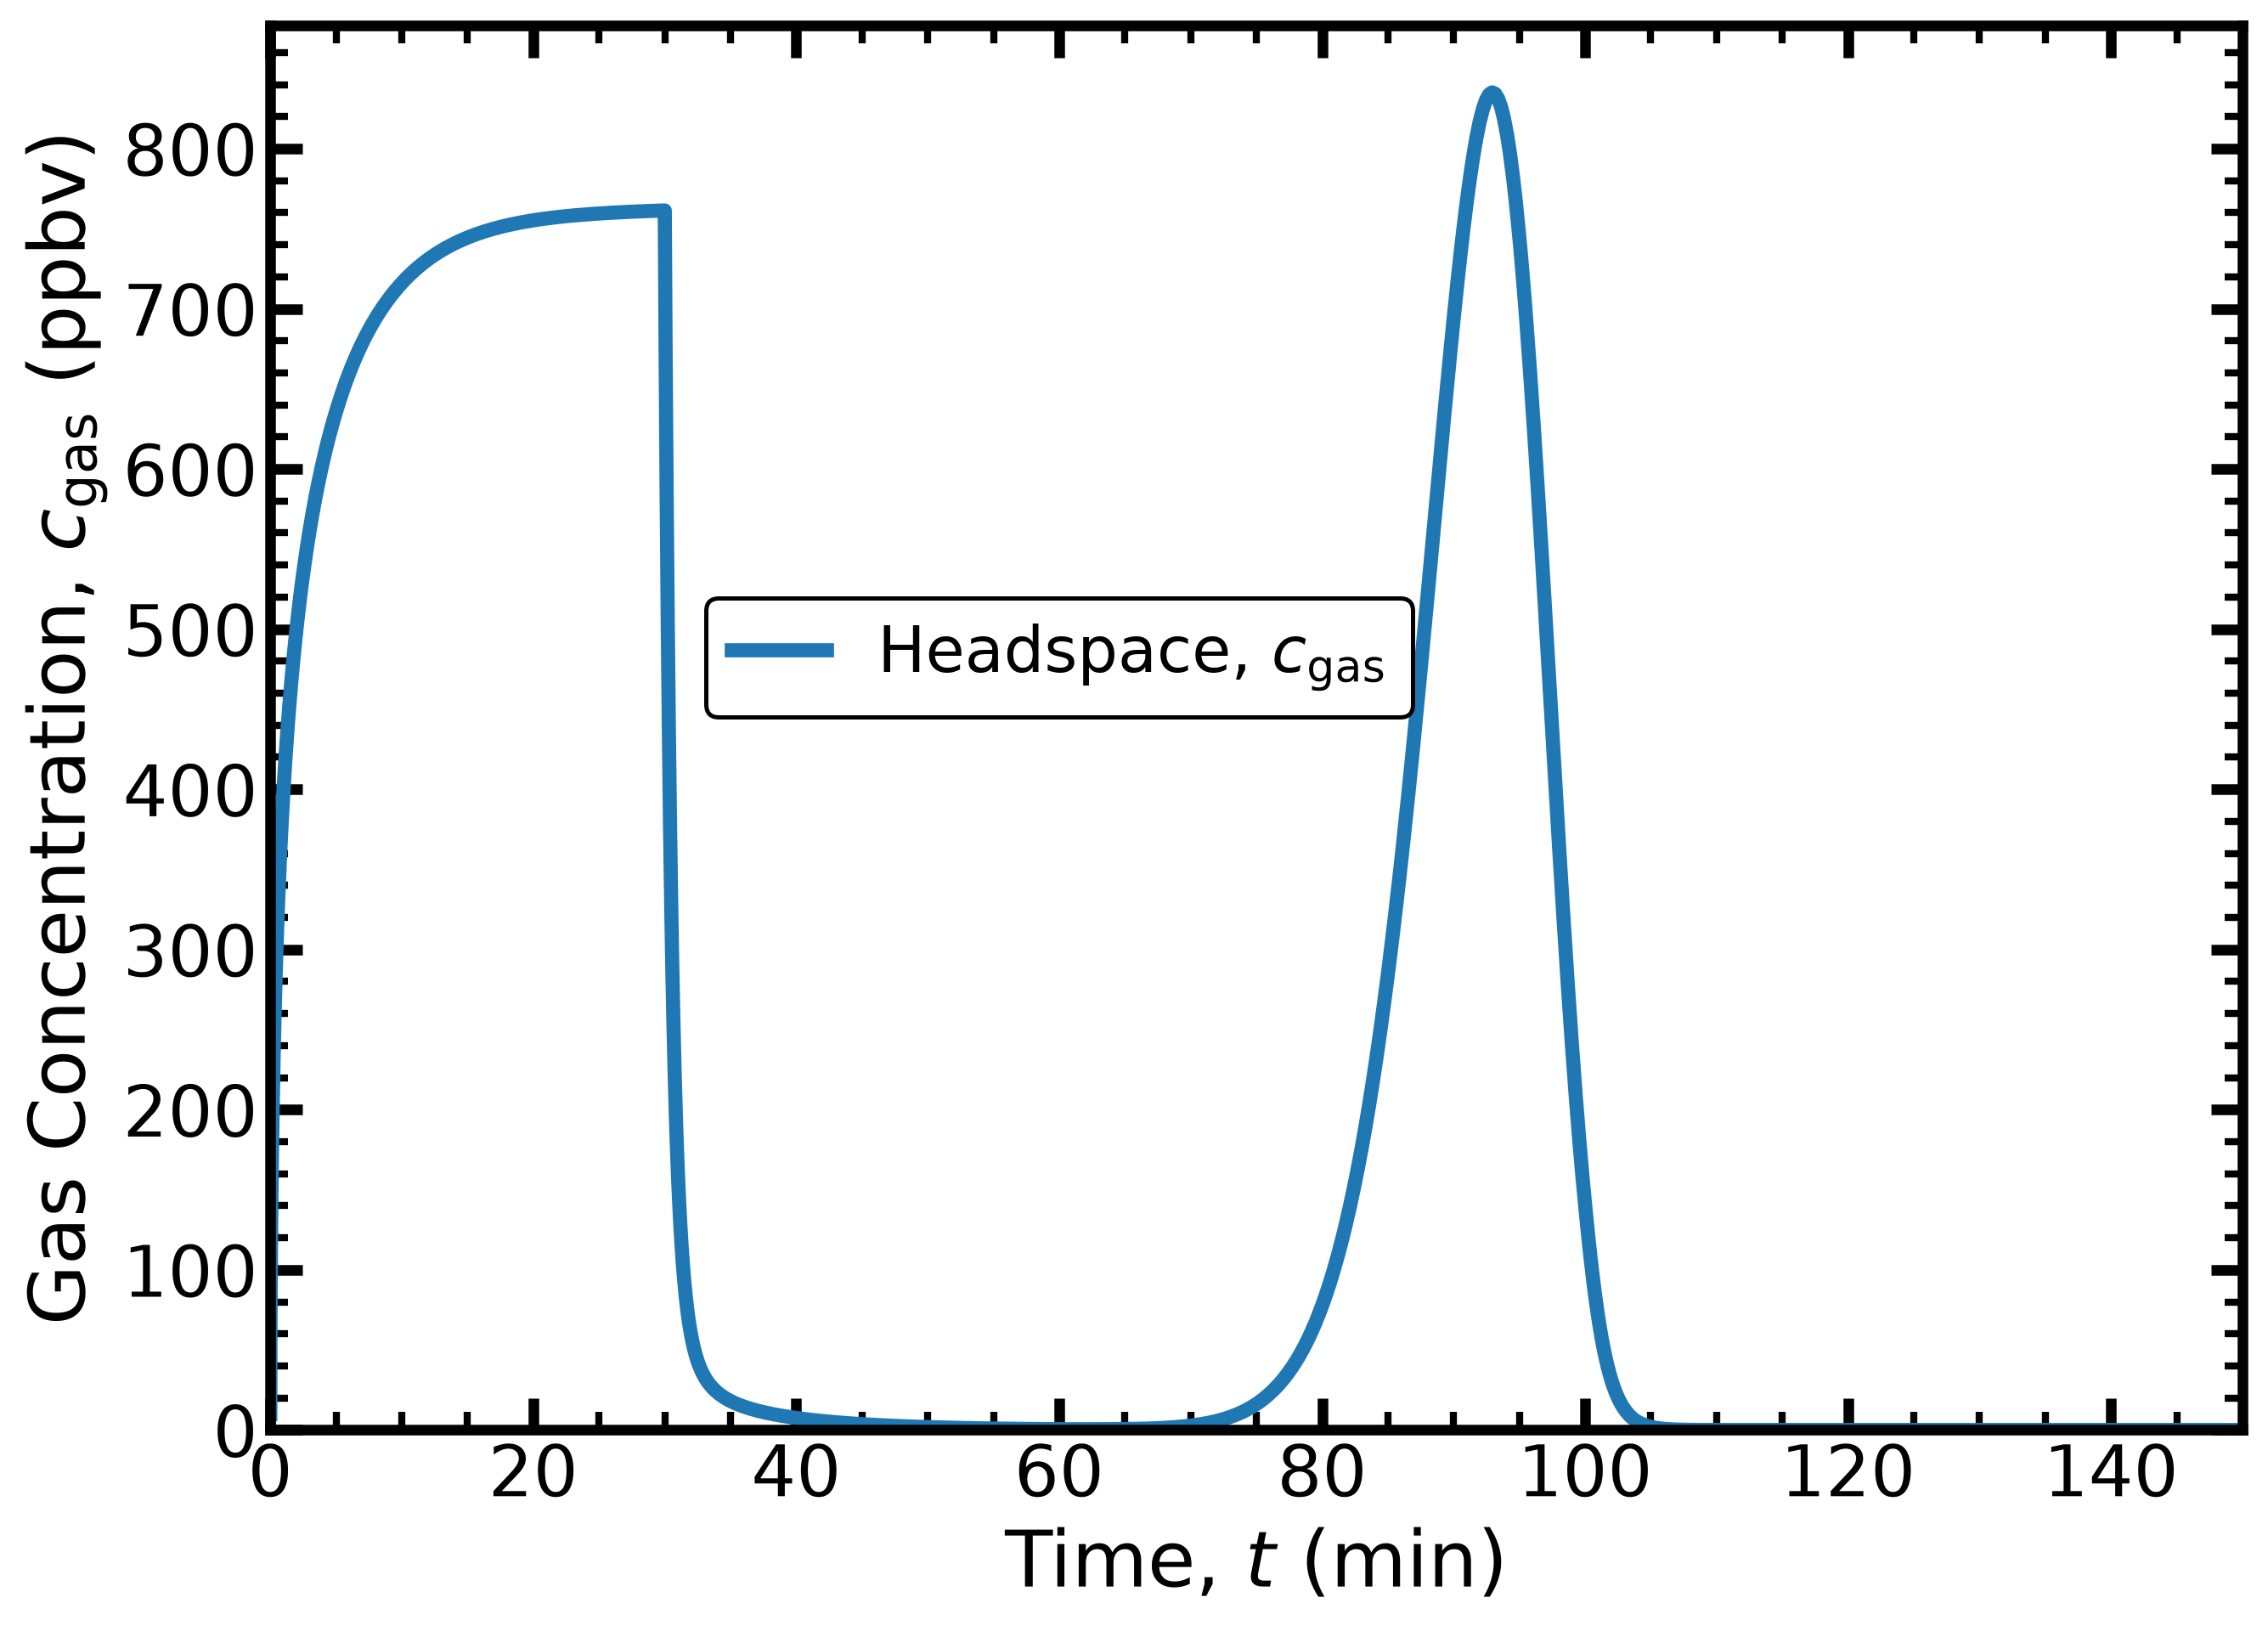

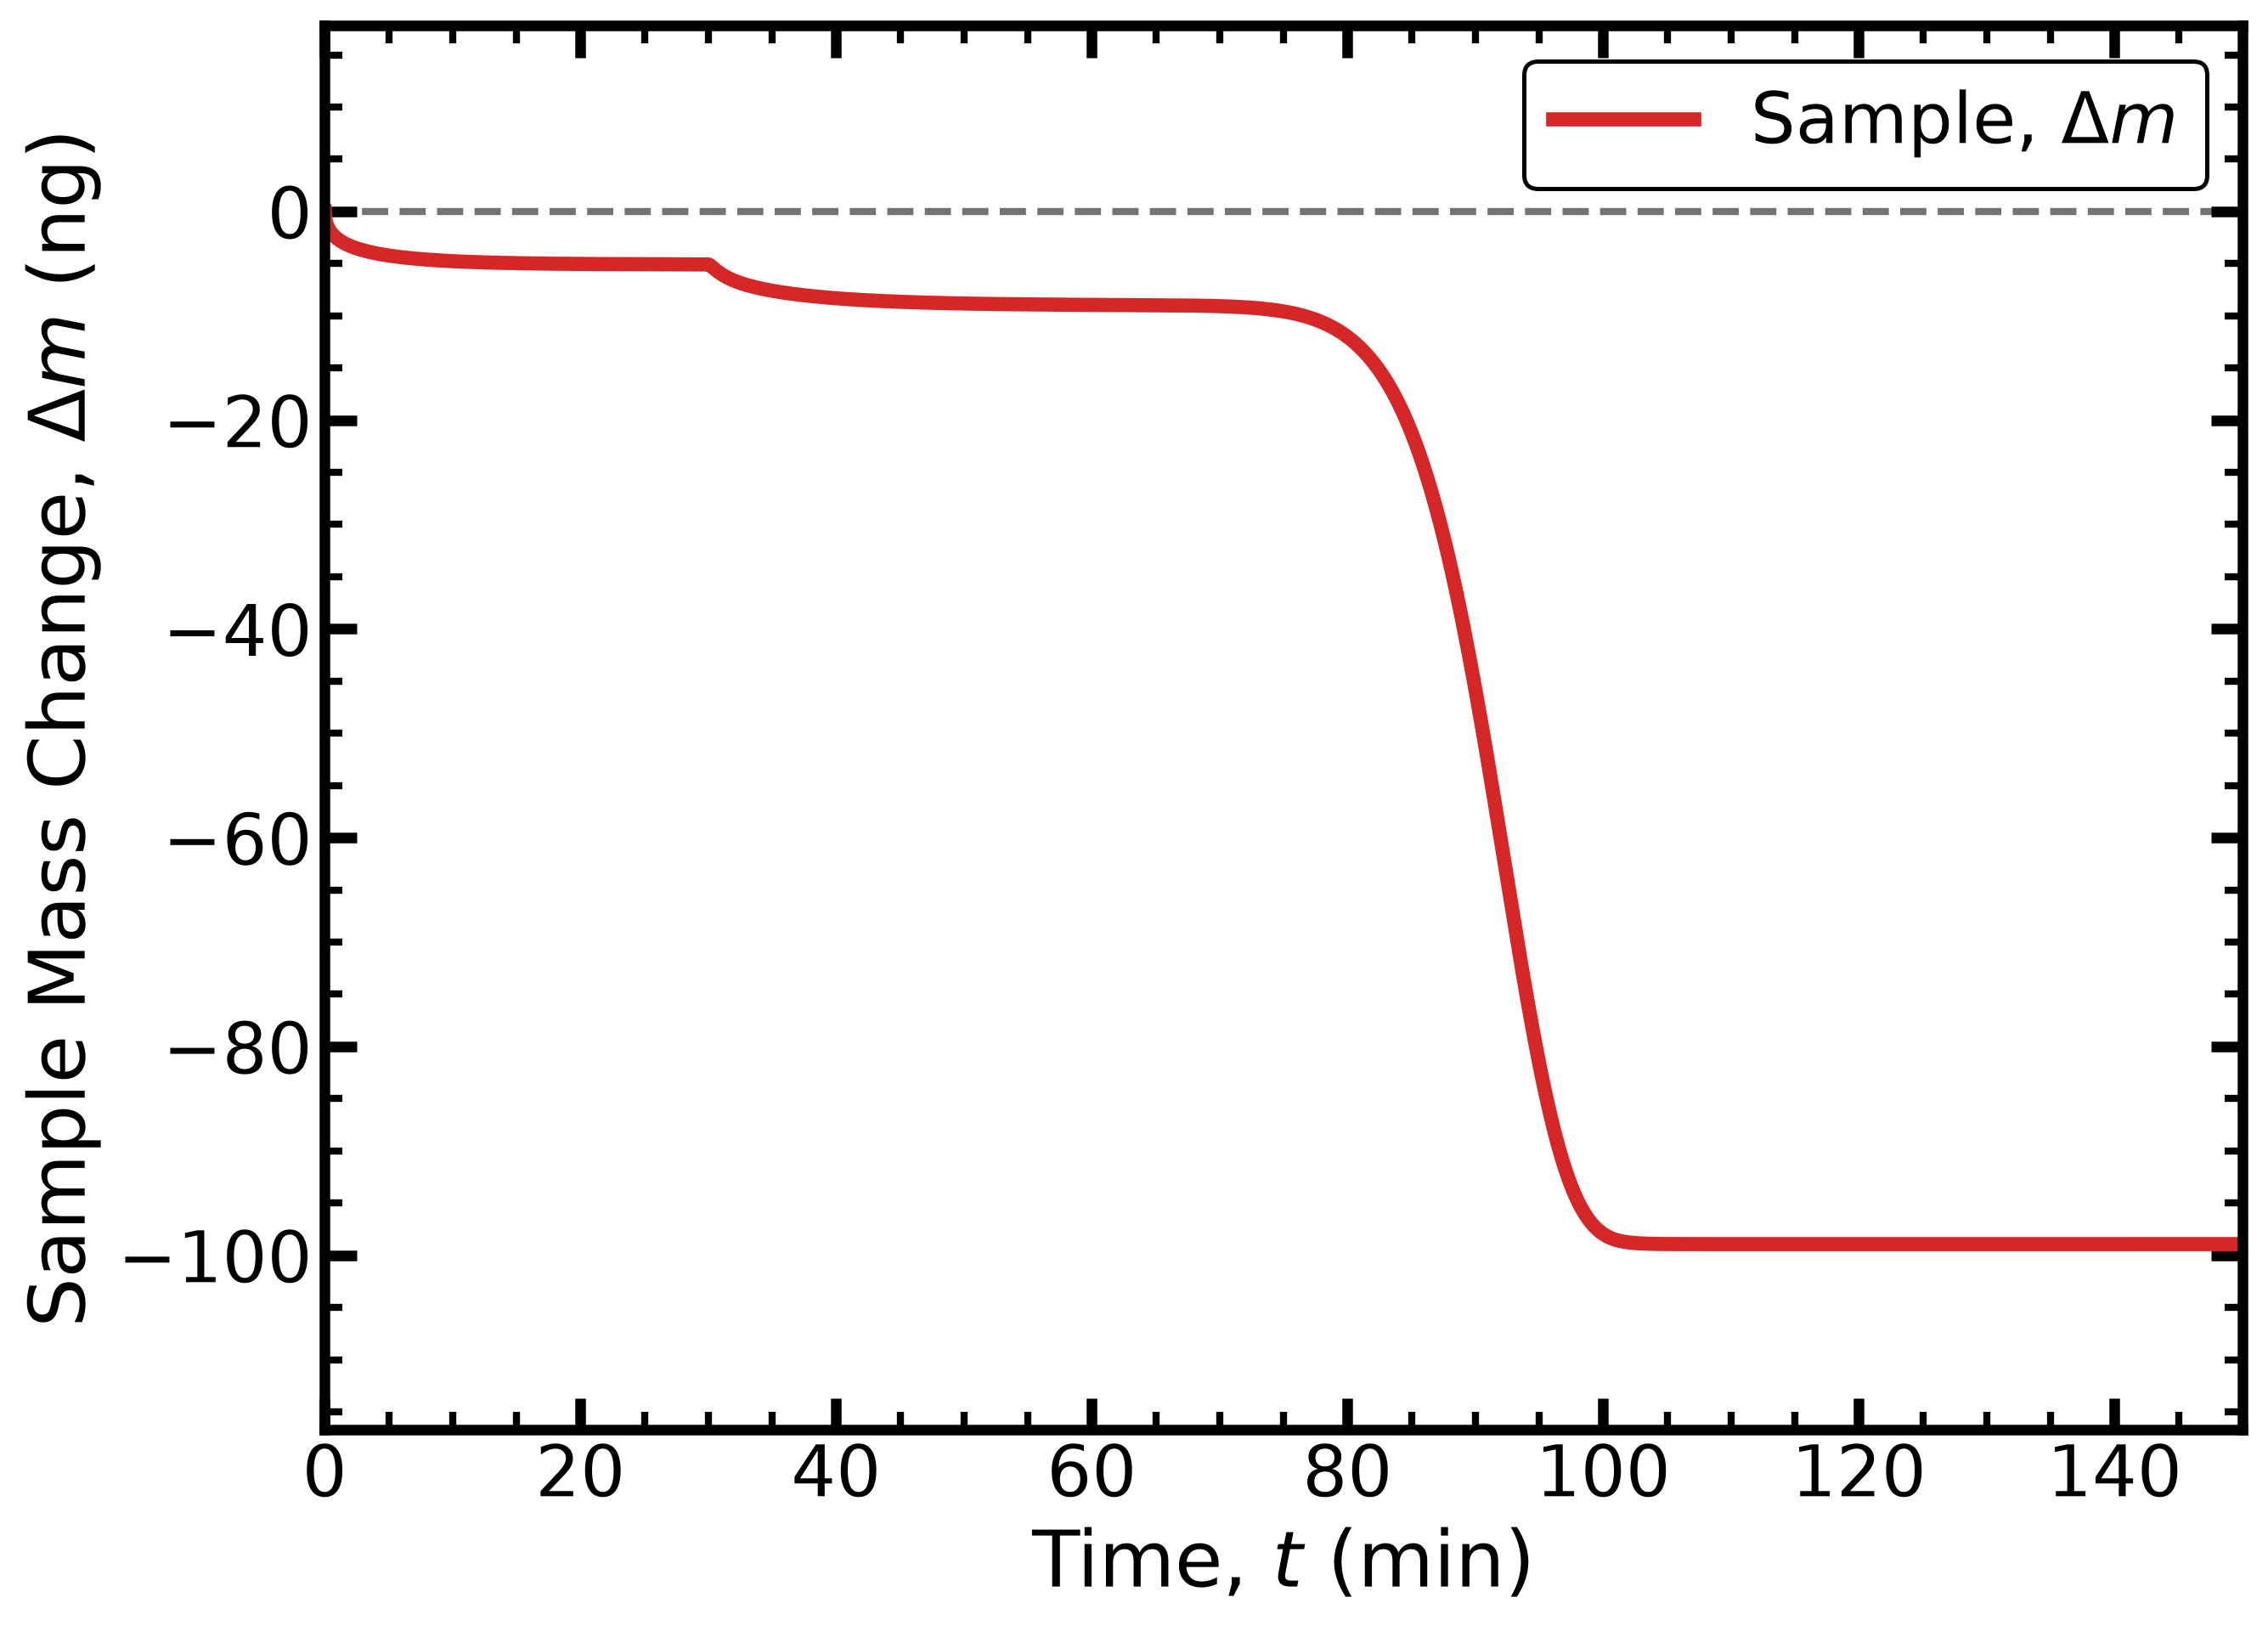

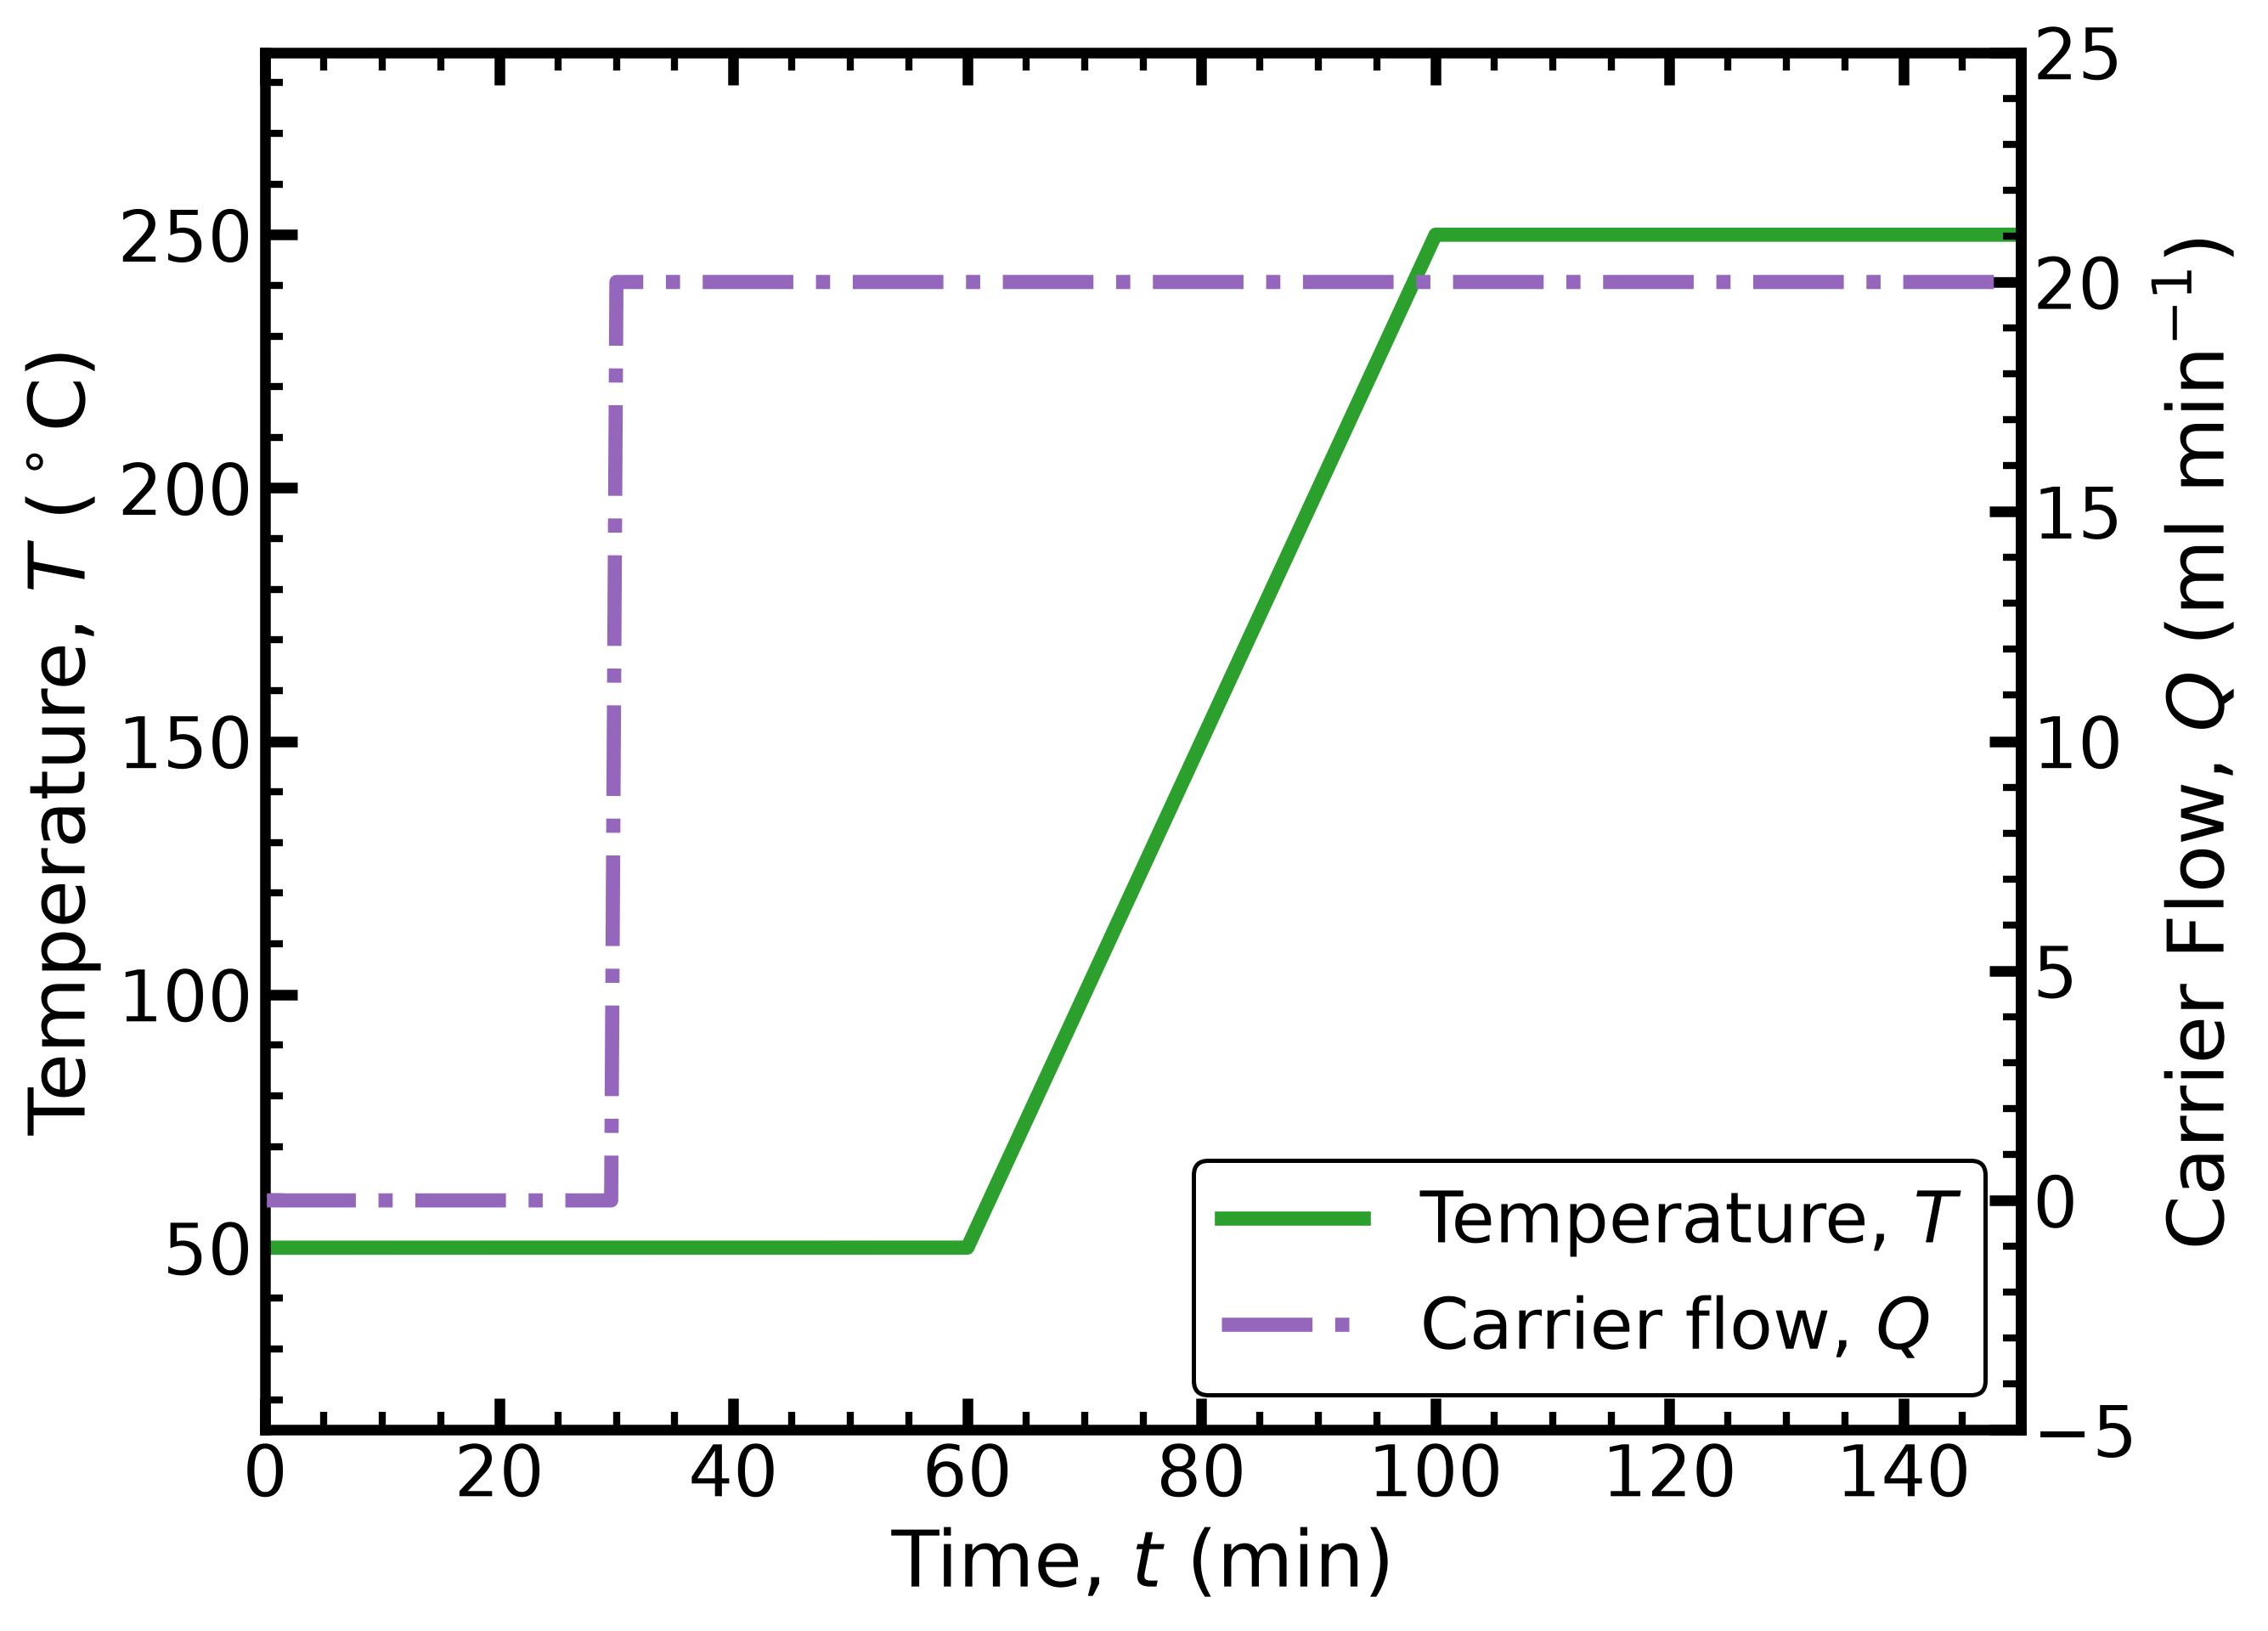

Solve time            : 0.302 s (4 smooth segments, 1907 RHS evaluations)
Conservation residual : 1.499566e-06 uM-equivalent
Normalized error      : 1.363e-06 %
Absolute boundary flux: 1.100000e+02


In [9]:
# Run the simulation
results = run_simulation(tfinal, temp_params, flow_params, cfeed_params,
                         m, R, mSample, rhoSample, Vvessel, MW_analyte,
                         src_params, DeltaHs, K50, D50, EaD, cD, F, c0free, cgas_init, N,
                         grid_scheme=grid_scheme, grid_stretch=grid_stretch,
                         rtol=rtol, atol=atol,
                         max_breakpoints=max_breakpoints,
                         max_solution_elements=max_solution_elements,
                         min_out_per_segment=min_out_per_segment)

import io
from IPython.display import Image, display
from matplotlib.ticker import AutoMinorLocator

TAB10 = plt.get_cmap('tab10').colors


def style_axes(ax, xlabel, ylabel, label_size=22, tick_size=20):
    """House figure style: full black box, inward major and minor ticks on all
    four sides, no top/right tick labels, no gridlines, large non-bold labels."""
    for side in ('top', 'bottom', 'left', 'right'):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(3)
        ax.spines[side].set_color('black')
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which='major', direction='in', length=9, width=3,
                   top=True, bottom=True, left=True, right=True,
                   labeltop=False, labelright=False, labelsize=tick_size)
    ax.tick_params(which='minor', direction='in', length=5, width=2,
                   top=True, bottom=True, left=True, right=True,
                   labeltop=False, labelright=False)
    ax.grid(False)
    ax.set_xlabel(xlabel, fontsize=label_size)
    ax.set_ylabel(ylabel, fontsize=label_size)


def boxed_legend(ax, handles=None, labels=None, loc='best', size=20, **kwargs):
    leg = (ax.legend(handles, labels, fontsize=size, loc=loc, **kwargs)
           if handles is not None else ax.legend(fontsize=size, loc=loc, **kwargs))
    leg.set_frame_on(True)
    leg.get_frame().set_linewidth(1.2)
    leg.get_frame().set_edgecolor('black')
    leg.get_frame().set_facecolor('white')
    leg.get_frame().set_alpha(1.0)
    return leg


def show(fig):
    """Render inline at 300 dpi, scaled to a comfortable width in VS Code."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=300, bbox_inches='tight')
    plt.close(fig)
    display(Image(buf.getvalue(), width=1000))


t = results['t (min)']

# ------------------------------------------------- Figure 1: concentrations
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)
ax.plot(t, results['c_gas (ppbv)'], color=TAB10[0], linewidth=4,
        label=r'Headspace, $c_\mathrm{gas}$')
if np.any(np.asarray(results['c_feed (ppbv)']) > 0):
    ax.plot(t, results['c_feed (ppbv)'], color=TAB10[1], linewidth=4,
            linestyle='--', label=r'Feed, $c_\mathrm{feed}$')
style_axes(ax, r'Time, $t$ (min)',
           r'Gas Concentration, $c_\mathrm{gas}$ (ppbv)')
ax.set_xlim(0, float(np.max(t)))
ax.set_ylim(bottom=0)
ax.margins(y=0.18)                      # headroom so the legend clears the data
boxed_legend(ax, loc='center', size=18, bbox_to_anchor=(0.40, 0.55),
             handlelength=1.5)
fig.tight_layout()
show(fig)

# --------------------------------------------------- Figure 2: mass change
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)
ax.axhline(y=0, color='0.45', linestyle='--', linewidth=2, zorder=1)
ax.plot(t, results['Δm (ng)'], color=TAB10[3], linewidth=4, zorder=2,
        label=r'Sample, $\Delta m$')
style_axes(ax, r'Time, $t$ (min)', r'Sample Mass Change, $\Delta m$ (ng)')
ax.set_xlim(0, float(np.max(t)))
ax.margins(y=0.18)
boxed_legend(ax, loc='upper right')
fig.tight_layout()
show(fig)

# ------------------------------------------- Figure 3: imposed forcing check
# Worth a look after the v13 change: every kink below is a segment boundary
# that the integrator now splits on rather than stepping across.
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)
l1, = ax.plot(t, results['T (C)'], color=TAB10[2], linewidth=4,
              label=r'Temperature, $T$')
style_axes(ax, r'Time, $t$ (min)', r'Temperature, $T$ ($^\circ$C)')
ax.set_xlim(0, float(np.max(t)))
ax.margins(y=0.18)

ax2 = ax.twinx()
l2, = ax2.plot(t, results['Q (ml/min)'], color=TAB10[4], linewidth=4,
               linestyle='-.', label=r'Carrier flow, $Q$')
ax2.set_ylabel(r'Carrier Flow, $Q$ (ml min$^{-1}$)', fontsize=22)
ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.tick_params(which='major', direction='in', length=9, width=3,
                right=True, labelright=True, labelsize=20)
ax2.tick_params(which='minor', direction='in', length=5, width=2, right=True)
ax2.spines['right'].set_linewidth(3)
ax2.grid(False)
ax2.margins(y=0.25)
boxed_legend(ax, handles=[l1, l2],
             labels=[l1.get_label(), l2.get_label()], loc='lower right')
fig.tight_layout()
show(fig)

print(f"Solve time            : {results['solve_time (s)']:.3f} s "
      f"({results['n_segments']} smooth segments, "
      f"{results['nfev']} RHS evaluations)")
print(f"Conservation residual : {results['mass_balance_residual']:.6e} uM-equivalent")
print(f"Normalized error      : {results['mass_balance_error (%)']:.3e} %")
print(f"Absolute boundary flux: {results['absolute_boundary_flux_integral']:.6e}")

# Safe tabular/export helpers. These exclude the differently sized spatial grid
# and metadata that make pd.DataFrame(results) invalid.
# display(results_to_dataframe(results).head())
# results_to_dataframe(results).to_clipboard(index=False)
# export_paths = export_simulation_results(results, 'moliere_results.csv')
# print(export_paths)
